# DataCo Smart Supply Chain — Late-Delivery Risk
## Notebook 1 — EDA & Preprocessing

**IT3091 · Group 2026-AI-05 · Guided Data Track (Logistics & Supply Chain)**

| Member | IT Number | Role |
|---|---|---|
| Bolonne B.R.M. | IT24102050 | Framing + EDA |
| Kodagoda D.S. | IT24101613 | Preprocessing + baseline |
| Jayasekara C.D. | IT24103494 | Advanced models + tuning |
| Liyanage J.L.K.L. | IT24101927 | Evaluation + recommendation |

Binary classification · one order line item per row · target `Late_delivery_risk` (1 = late)
Data: 180,519 × 53, Jan 2015 – Jan 2018.

**Rule:** split before exploring. All EDA uses train only; all encoders/scalers fit on train only.
Clickstream file excluded — no `Order Id`, cannot be joined.

---
## 0 · Setup

In [1]:
# SETUP: seed, paths, split dates and the plot theme, all in one place.
# WHY here: reproducibility. RANDOM_STATE=42 is reused by every model and split,
# so re-running gives identical numbers. The two split dates are declared here
# rather than buried later, so the split rule is auditable.

# --- Core libraries -------------------------------------------------------
import os, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# --- Reproducibility ------------------------------------------------------
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# --- Paths ----------------------------------------------------------------
DATA_DIR  = Path(".")                      # folder holding the CSVs
RAW_CSV   = DATA_DIR / "DataCoSupplyChainDataset.csv"
DICT_CSV  = DATA_DIR / "DescriptionDataCoSupplyChain.csv"
ART_DIR   = Path("artifacts"); ART_DIR.mkdir(exist_ok=True)
FIG_DIR   = Path("figures");   FIG_DIR.mkdir(exist_ok=True)

# --- Temporal split boundaries (justified in Section 8) -------------------
VAL_START  = pd.Timestamp("2016-11-01")    # train  : orders before this date
TEST_START = pd.Timestamp("2017-05-01")    # val    : VAL_START <= date < TEST_START
                                           # test   : date >= TEST_START

TARGET = "Late_delivery_risk"

# --- Plotting theme -------------------------------------------------------
# Validated categorical palette; hues are assigned in fixed slot order, never cycled.
C_BLUE, C_ORANGE, C_AQUA, C_YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
C_MAGENTA, C_GREEN, C_VIOLET, C_RED = "#e87ba4", "#008300", "#4a3aa7", "#e34948"
SURFACE, INK, INK_2, INK_MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#8f8e88"

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.size": 10, "font.family": "DejaVu Sans",
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlepad": 12,
    "axes.titlecolor": INK, "axes.labelcolor": INK_2, "axes.labelsize": 9.5,
    "text.color": INK, "xtick.color": INK_2, "ytick.color": INK_2,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.edgecolor": "#d9d8d2",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e8e7e1",
    "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2, "lines.markersize": 6,
})

def finish(ax, title=None, subtitle=None, xlabel=None, ylabel=None, pct=False, hgrid=False):
    """Apply the shared chart anatomy: title block, recessive axes, optional % formatting."""
    if hgrid:
        ax.grid(axis="x", color="#e8e7e1", linewidth=0.8); ax.grid(axis="y", visible=False)
    if title:
        # Leave room above the axes for the subtitle so the two never collide.
        ax.set_title(title, loc="left", pad=26 if subtitle else 12)
    if subtitle:
        ax.text(0, 1.015, subtitle, transform=ax.transAxes, fontsize=9,
                color=INK_MUTED, va="bottom", ha="left")
    ax.set_xlabel(xlabel or "", labelpad=8); ax.set_ylabel(ylabel or "", labelpad=8)
    if pct:
        (ax.xaxis if hgrid else ax.yaxis).set_major_formatter(PercentFormatter(1.0, decimals=0))
    return ax

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")

def fmt(frame, spec=None, decimals=4):
    """Pretty-print a DataFrame without pandas' .style accessor (which needs jinja2)."""
    out, spec = frame.copy(), (spec or {})
    for c in out.columns:
        if c in spec:
            out[c] = out[c].map(lambda v, s=spec[c]: format(v, s))
        elif pd.api.types.is_float_dtype(out[c]):
            out[c] = out[c].round(decimals)
    return out

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
print(f"pandas {pd.__version__} | numpy {np.__version__} | seed {RANDOM_STATE}")

pandas 3.0.6 | numpy 2.5.3 | seed 42


---
## 1 · Load

`encoding='latin-1'` — file is not UTF-8; Spanish place names would corrupt into extra categories.

In [2]:
# LOAD the raw CSV and parse the two date columns.
# WHY latin-1: the file is NOT UTF-8. Spanish place names ("Rajastan", "Cordoba")
# would turn into mojibake, and one real category would split into two during
# one-hot encoding. Always declare the encoding rather than let pandas guess.

DATE_COLS = ["order date (DateOrders)", "shipping date (DateOrders)"]

raw = pd.read_csv(RAW_CSV, encoding="latin-1")
for c in DATE_COLS:
    raw[c] = pd.to_datetime(raw[c], format="%m/%d/%Y %H:%M")

print(f"Rows: {raw.shape[0]:,}   Columns: {raw.shape[1]}")
print(f"Order dates: {raw[DATE_COLS[0]].min():%Y-%m-%d}  ->  {raw[DATE_COLS[0]].max():%Y-%m-%d}")
print(f"Memory: {raw.memory_usage(deep=True).sum()/1e6:,.0f} MB")
raw.head(3)

Rows: 180,519   Columns: 53
Order dates: 2015-01-01  ->  2018-01-31
Memory: 129 MB


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,2018-01-31 22:56:00,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-02-03 22:56:00,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,2018-01-13 12:27:00,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-18 12:27:00,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,2018-01-13 12:06:00,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-17 12:06:00,Standard Class


---
## 2 · Data understanding

### 2.1 · Column audit

In [3]:
# AUDIT TABLE: join the supplied data dictionary to the MEASURED properties of
# each column (dtype, distinct values, % missing, an example value).
# WHY: .info() is not evidence. This one table is what every drop decision in
# Section 7 is justified against, so the reasoning is visible, not implicit.

# Read the supplied data dictionary and normalise its keys so they join to the real column names.
ddict = pd.read_csv(DICT_CSV)
ddict.columns = ["field", "description"]
ddict["field"] = ddict["field"].str.strip()
ddict["description"] = ddict["description"].str.lstrip(": ").str.strip()

def norm(s):
    return s.strip().lower().replace("_", " ")

desc_map = {norm(f): d for f, d in zip(ddict["field"], ddict["description"])}

audit = pd.DataFrame({
    "dtype":      raw.dtypes.astype(str),
    "n_unique":   raw.nunique(),
    "n_missing":  raw.isna().sum(),
    "pct_missing": (raw.isna().mean() * 100).round(2),
    "example":    raw.iloc[0].astype(str).str.slice(0, 32),
})
audit["description"] = [desc_map.get(norm(c), "-") for c in audit.index]
audit.index.name = "column"
audit

,dtype,n_unique,n_missing,pct_missing,example,description
column,,,,,,
Type,str,4,0,0.00,DEBIT,Type of transaction made
Days for shipping (real),int64,7,0,0.00,3,Actual shipping days of the purchased product
Days for shipment (scheduled),int64,4,0,0.00,4,Days of scheduled delivery of the purchased pr...
Benefit per order,float64,21998,0,0.00,91.25,Earnings per order placed
Sales per customer,float64,2927,0,0.00,314.6400146,Total sales per customer made per customer
Delivery Status,str,4,0,0.00,Advance shipping,"Delivery status of orders: Advance shipping , ..."
Late_delivery_risk,int64,2,0,0.00,0,Categorical variable that indicates if sending...
Category Id,int64,51,0,0.00,73,Product category code
Category Name,str,50,0,0.00,Sporting Goods,Description of the product category


In [4]:
# STRUCTURAL FLAGS: find constant, all-null, mostly-missing and high-cardinality
# columns programmatically instead of by eye.
# KEY NUMBER: 180,519 rows but only 65,752 orders => ~2.7 line items per order.
# That single fact is why we cannot use a random split (see Section 8).

# --- Quick structural flags -------------------------------------------------
constant_cols  = [c for c in raw.columns if raw[c].nunique(dropna=False) <= 1]
allnull_cols   = [c for c in raw.columns if raw[c].isna().all()]
highmiss_cols  = [c for c in raw.columns if 0.40 < raw[c].isna().mean() < 1.0]
highcard_cols  = [c for c in raw.columns
                  if pd.api.types.is_string_dtype(raw[c]) and raw[c].nunique() > 200]

print("Columns with a single constant value :", constant_cols)
print("Columns that are entirely null       :", allnull_cols)
print("Columns >40% missing (not all-null)  :", highmiss_cols)
print("High-cardinality text columns (>200) :", highcard_cols)
print()
print("Exact duplicate rows        :", raw.duplicated().sum())
print("Duplicate 'Order Item Id'   :", raw["Order Item Id"].duplicated().sum())
print("Distinct orders ('Order Id'):", f"{raw['Order Id'].nunique():,}"
      f"  ->  {raw.shape[0]/raw['Order Id'].nunique():.2f} line items per order on average")

Columns with a single constant value : ['Customer Email', 'Customer Password', 'Product Description', 'Product Status']
Columns that are entirely null       : ['Product Description']
Columns >40% missing (not all-null)  : ['Order Zipcode']
High-cardinality text columns (>200) : ['Customer City', 'Customer Fname', 'Customer Lname', 'Customer Street', 'Order City', 'Order State']

Exact duplicate rows        : 0
Duplicate 'Order Item Id'   : 0
Distinct orders ('Order Id'): 65,752  ->  2.75 line items per order on average


180,519 rows = only 65,752 orders (~2.7 line items each). This decides the split — see §8.

### 2.2 · First-look EDA (raw data — target not used)

Descriptive only, so it is safe before the split. Target relationships start in §9.

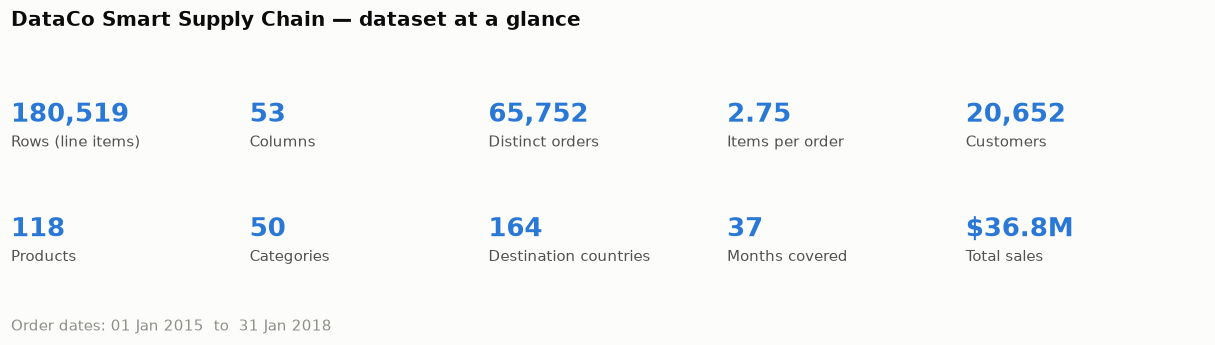

In [5]:
# DATASET AT A GLANCE - the headline numbers as a KPI strip.
# WHY first: it anchors every later statement. "2.75 items per order" is the
# single most important number here - it is why a random split would leak.
stats = [
    ("Rows (line items)",  f"{len(raw):,}"),
    ("Columns",            f"{raw.shape[1]}"),
    ("Distinct orders",    f"{raw['Order Id'].nunique():,}"),
    ("Items per order",    f"{len(raw)/raw['Order Id'].nunique():.2f}"),
    ("Customers",          f"{raw['Customer Id'].nunique():,}"),
    ("Products",           f"{raw['Product Card Id'].nunique():,}"),
    ("Categories",         f"{raw['Category Name'].nunique()}"),
    ("Destination countries", f"{raw['Order Country'].nunique()}"),
    ("Months covered",     f"{raw[DATE_COLS[0]].dt.to_period('M').nunique()}"),
    ("Total sales",        f"${raw['Sales'].sum()/1e6:,.1f}M"),
]

fig, ax = plt.subplots(figsize=(14, 2.6))
ax.axis("off")
for k, (label, value) in enumerate(stats):
    x = (k % 5) / 5
    y = 0.62 - (k // 5) * 0.52
    # shrink the font if a value would run into the next tile
    fs = 17 if len(value) <= 9 else 13
    ax.text(x, y, value, fontsize=fs, fontweight="bold", color=C_BLUE,
            transform=ax.transAxes, va="bottom")
    ax.text(x, y - 0.1, label, fontsize=9.5, color=INK_2,
            transform=ax.transAxes, va="bottom")
ax.text(0, -0.30, f"Order dates: {raw[DATE_COLS[0]].min():%d %b %Y}  to  "
                  f"{raw[DATE_COLS[0]].max():%d %b %Y}",
        fontsize=9.5, color=INK_MUTED, transform=ax.transAxes)
ax.set_title("DataCo Smart Supply Chain — dataset at a glance", loc="left", fontsize=13)
save(fig, "00_overview"); plt.show()

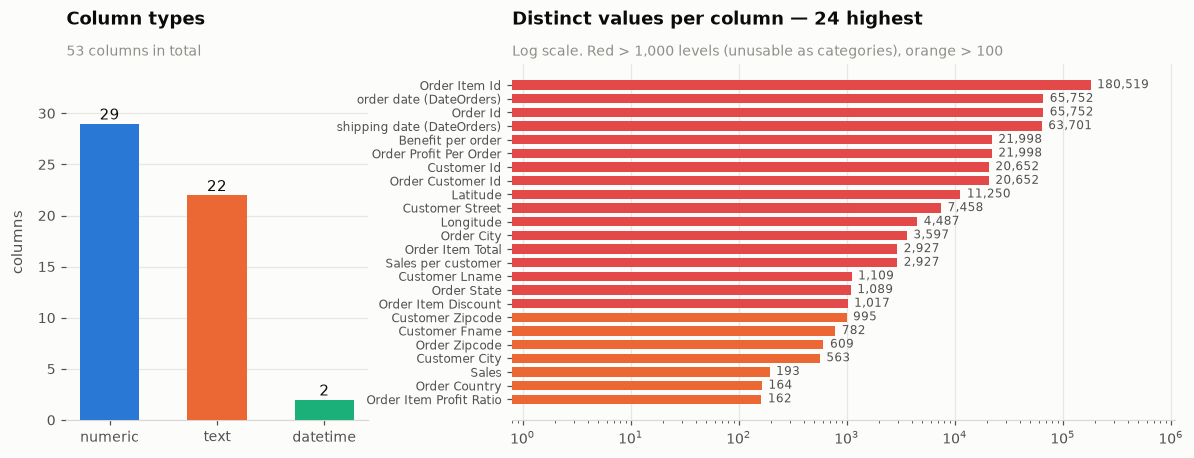

In [6]:
# Column types, and distinct values per column on a LOG scale.
# WHY log: cardinality spans 1 to 180,519, so a linear axis would hide everything.
# Red bars (>1,000 levels) are unusable as categories - one-hot would create
# thousands of sparse columns. This is what drives the drops in Section 7.

# --- Column types and cardinality ------------------------------------------
kinds = pd.Series({
    "numeric":     raw.select_dtypes(include=np.number).shape[1],
    "text":        sum(pd.api.types.is_string_dtype(raw[c]) for c in raw.columns),
    "datetime":    raw.select_dtypes(include="datetime64[ns]").shape[1],
})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2),
                         gridspec_kw={"width_ratios": [1, 2.2], "wspace": 0.3})

ax = axes[0]
ax.bar(kinds.index, kinds.values, color=[C_BLUE, C_ORANGE, C_AQUA], width=.55, zorder=3)
for i, v in enumerate(kinds.values):
    ax.text(i, v + .4, str(v), ha="center", fontsize=10, color=INK)
ax.set_ylim(0, kinds.max() * 1.2)
finish(ax, "Column types", f"{raw.shape[1]} columns in total", ylabel="columns")

# Cardinality on a log scale -- it spans 1 to 180,519.
card = raw.nunique().sort_values(ascending=False).head(24)
ax = axes[1]
y = np.arange(len(card))[::-1]
cols = [C_RED if v > 1000 else (C_ORANGE if v > 100 else C_BLUE) for v in card.values]
ax.barh(y, card.values, color=cols, height=.68, zorder=3)
ax.set_xscale("log")
ax.set_yticks(y); ax.set_yticklabels(card.index, fontsize=8)
for yi, v in zip(y, card.values):
    ax.text(v * 1.15, yi, f"{v:,}", va="center", fontsize=8, color=INK_2)
ax.set_xlim(0.8, card.max() * 6)
finish(ax, "Distinct values per column — 24 highest",
       "Log scale. Red > 1,000 levels (unusable as categories), orange > 100", hgrid=True)
save(fig, "00a_types_cardinality"); plt.show()

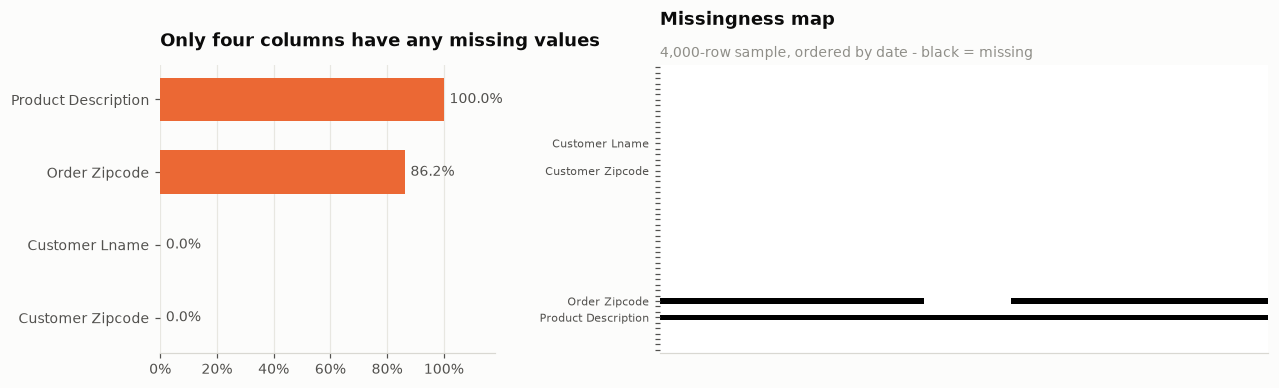

In [7]:
# Missingness: a bar chart of the rate, plus a MAP of where the gaps fall.
# WHY the map: it shows whether gaps are random (speckle) or structural (bands).
# Order Zipcode's gaps form bands => the field only applies to some destinations,
# so imputing it would be inventing data. We drop it instead.

# --- Missingness across every column ---------------------------------------
miss_all = (raw.isna().mean().sort_values(ascending=False))
miss_all = miss_all[miss_all > 0]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4),
                         gridspec_kw={"width_ratios": [1.1, 2], "wspace": 0.35})

ax = axes[0]
y = np.arange(len(miss_all))[::-1]
ax.barh(y, miss_all.values, color=C_ORANGE, height=.6, zorder=3)
ax.set_yticks(y); ax.set_yticklabels(miss_all.index, fontsize=9)
for yi, v in zip(y, miss_all.values):
    ax.text(v + .02, yi, f"{v:.1%}", va="center", fontsize=9, color=INK_2)
ax.set_xlim(0, 1.18)
finish(ax, "Only four columns have any missing values", None, pct=True, hgrid=True)

# A missingness map: are the gaps random or structured?
samp = raw.sample(4000, random_state=RANDOM_STATE).sort_values("order date (DateOrders)")
ax = axes[1]
ax.imshow(samp.isna().T.to_numpy(), aspect="auto", cmap="Greys",
          interpolation="nearest", vmin=0, vmax=1)
ax.set_yticks(range(raw.shape[1]))
ax.set_yticklabels([c if c in set(miss_all.index) else "" for c in raw.columns], fontsize=7)
ax.set_xticks([])
ax.grid(False)
finish(ax, "Missingness map", "4,000-row sample, ordered by date - black = missing")
save(fig, "00b_missingness_raw"); plt.show()

Missingness is tiny and concentrated; all four affected columns are dropped in §7 anyway.

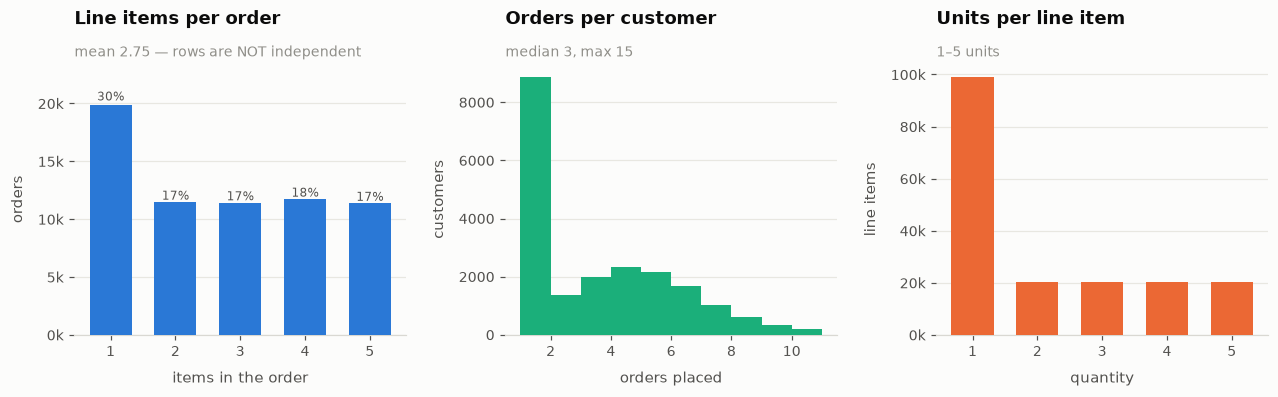

In [8]:
# GRAIN OF THE DATA - how many line items per order, orders per customer?
# WHY this matters more than it looks: the left panel is the evidence for the
# split decision in Section 8. If one order spans several rows and they all
# share one label, a random row split puts the answer on both sides.
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2), gridspec_kw={"wspace": 0.3})

ipo = raw.groupby("Order Id").size().value_counts().sort_index()
ax = axes[0]
ax.bar(ipo.index, ipo.values, color=C_BLUE, width=.65, zorder=3)
for x, v in zip(ipo.index, ipo.values):
    ax.text(x, v * 1.02, f"{v/ipo.sum():.0%}", ha="center", fontsize=8, color=INK_2)
ax.set_ylim(0, ipo.max() * 1.18)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
finish(ax, "Line items per order",
       f"mean {len(raw)/raw['Order Id'].nunique():.2f} — rows are NOT independent",
       xlabel="items in the order", ylabel="orders")

opc = raw.groupby("Customer Id")["Order Id"].nunique()
ax = axes[1]
ax.hist(opc, bins=range(1, int(opc.quantile(.99)) + 2), color=C_AQUA,
        linewidth=0, zorder=3)
finish(ax, "Orders per customer", f"median {opc.median():.0f}, max {opc.max()}",
       xlabel="orders placed", ylabel="customers")

ax = axes[2]
qty = raw["Order Item Quantity"].value_counts().sort_index()
ax.bar(qty.index, qty.values, color=C_ORANGE, width=.65, zorder=3)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
finish(ax, "Units per line item", "1–5 units", xlabel="quantity", ylabel="line items")

save(fig, "00g_data_grain"); plt.show()

**The left panel drives §8.** Rows are line items, not orders, so they are not independent — a random split would put the same order (and its label) on both sides.

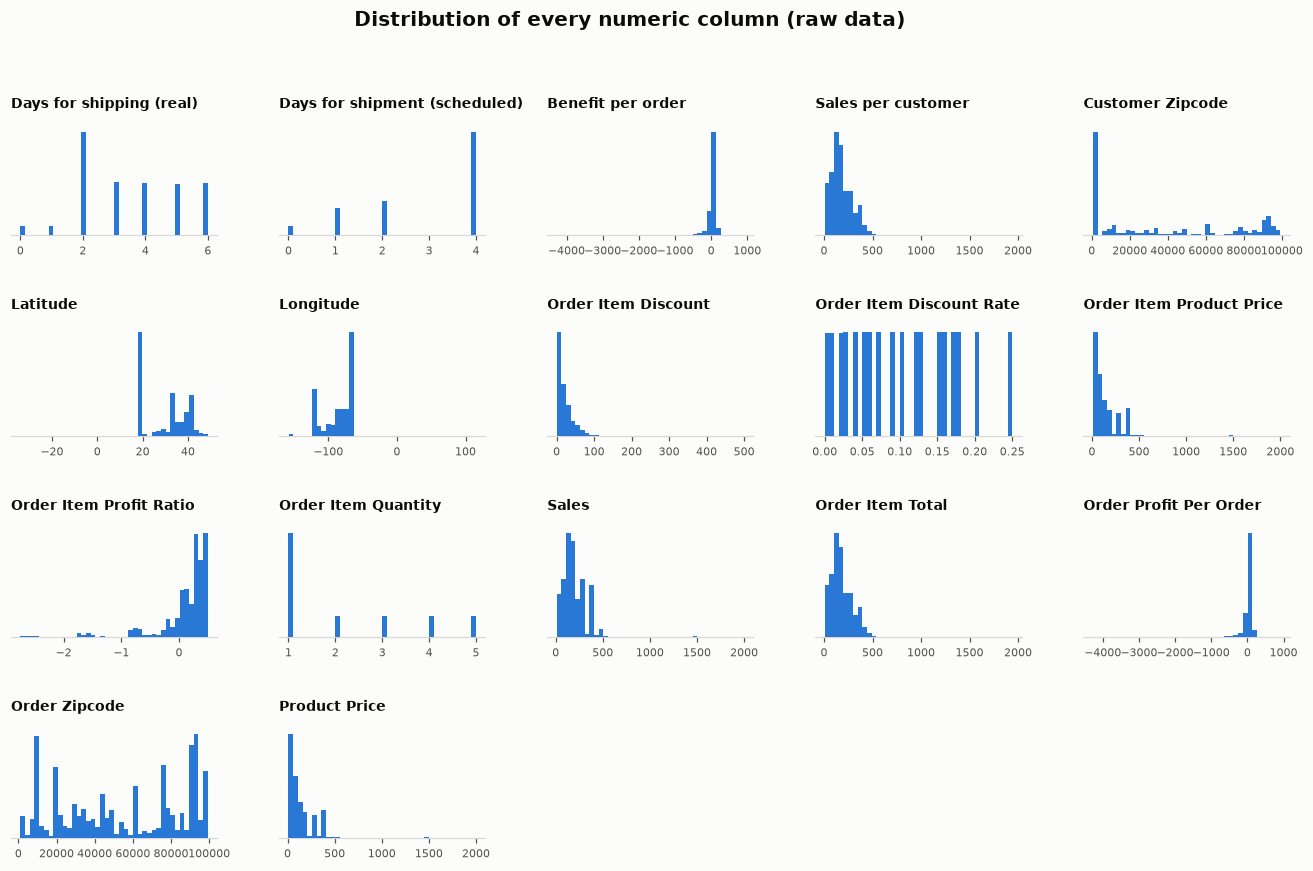

In [9]:
# Histogram of every numeric column, before any cleaning.
# WHY: shows shape (skew, spikes, bounded ranges) at a glance and tells us which
# columns need scaling versus which are already well behaved.

# --- Distributions of every numeric column ---------------------------------
num_profile = [c for c in raw.select_dtypes(include=np.number).columns
               if raw[c].nunique() > 2 and "Id" not in c]

n = len(num_profile); ncol = 5; nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.0*ncol, 2.1*nrow),
                         gridspec_kw={"hspace": 0.85, "wspace": 0.3})
for ax, col in zip(axes.ravel(), num_profile):
    ax.hist(raw[col].dropna(), bins=40, color=C_BLUE, linewidth=0, zorder=3)
    ax.set_title(col, loc="left", fontsize=9, fontweight="bold")
    ax.set_yticks([]); ax.tick_params(labelsize=7.5)
for ax in axes.ravel()[n:]:
    ax.set_visible(False)
fig.suptitle("Distribution of every numeric column (raw data)",
             x=0.5, y=1.005, fontsize=13, fontweight="bold", color=INK)
save(fig, "00c_numeric_histograms"); plt.show()

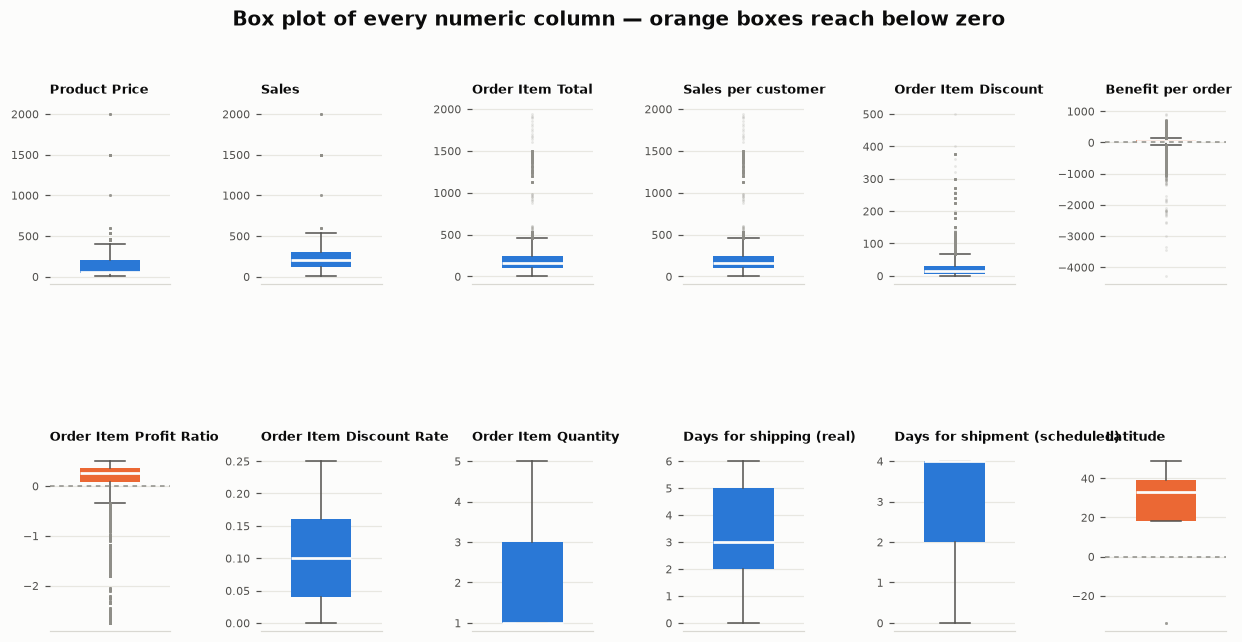

,count,mean,std,min,25%,50%,75%,max
Product Price,180519.0,141.23,139.73,9.99,50.00,59.99,199.99,1999.99
Sales,180519.0,203.77,132.27,9.99,119.98,199.92,299.95,1999.99
Order Item Total,180519.0,183.11,120.04,7.49,104.38,163.99,247.40,1939.99
Sales per customer,180519.0,183.11,120.04,7.49,104.38,163.99,247.40,1939.99
Order Item Discount,180519.0,20.66,21.80,0.00,5.40,14.00,29.99,500.00
Benefit per order,180519.0,21.97,104.43,-4274.98,7.00,31.52,64.80,911.80
Order Item Profit Ratio,180519.0,0.12,0.47,-2.75,0.08,0.27,0.36,0.50
Order Item Discount Rate,180519.0,0.10,0.07,0.00,0.04,0.10,0.16,0.25
Order Item Quantity,180519.0,2.13,1.45,1.00,1.00,1.00,3.00,5.00
Days for shipping (real),180519.0,3.50,1.62,0.00,2.00,3.00,5.00,6.00


In [10]:
# BOX PLOTS of every numeric column, each on its own axis.
# WHY separate axes: these span cents to thousands of dollars and 0-6 days;
# a shared axis would flatten most of them into a line.
# READ: monetary columns are right-skewed with long tails. Those are GENUINE
# high-value orders, not errors, so we KEEP them and handle skew by scaling.
# Orange boxes reach below zero = loss-making orders (post-hoc accounting).

# --- Box plots: the outlier and skew view ----------------------------------
# Each column gets its own axis -- these variables span wildly different scales
# (cents to thousands of dollars, and 0-6 days), so one shared axis would hide most of them.
box_profile = ["Product Price", "Sales", "Order Item Total", "Sales per customer",
               "Order Item Discount", "Benefit per order", "Order Item Profit Ratio",
               "Order Item Discount Rate", "Order Item Quantity",
               "Days for shipping (real)", "Days for shipment (scheduled)", "Latitude"]

ncol = 6; nrow = 2
fig, axes = plt.subplots(nrow, ncol, figsize=(2.3*ncol, 3.1*nrow),
                         gridspec_kw={"hspace": 0.95, "wspace": 0.75})
for ax, col in zip(axes.ravel(), box_profile):
    s = raw[col].dropna().to_numpy()
    neg = s.min() < 0
    bp = ax.boxplot([s], widths=.5, patch_artist=True, showfliers=True,
                    flierprops=dict(marker="o", markersize=1.8, markerfacecolor=INK_MUTED,
                                    markeredgecolor="none", alpha=.20),
                    medianprops=dict(color=SURFACE, linewidth=1.8),
                    whiskerprops=dict(color=INK_2, linewidth=1),
                    capprops=dict(color=INK_2, linewidth=1))
    bp["boxes"][0].set_facecolor(C_ORANGE if neg else C_BLUE)
    bp["boxes"][0].set_edgecolor("none")
    if neg:
        ax.axhline(0, color=INK_MUTED, linestyle=(0, (3, 3)), linewidth=1, zorder=4)
    ax.set_xticks([]); ax.tick_params(labelsize=7.5)
    ax.set_title(col, loc="left", fontsize=8.5, fontweight="bold", pad=8)
for ax in axes.ravel()[len(box_profile):]:
    ax.set_visible(False)
fig.suptitle("Box plot of every numeric column — orange boxes reach below zero",
             x=0.5, y=1.02, fontsize=13, fontweight="bold", color=INK)
save(fig, "00d_boxplots_raw"); plt.show()

raw[box_profile].describe().T.round(2)

Monetary columns are right-skewed with genuine high-value orders → **keep outliers**, handle by scaling.

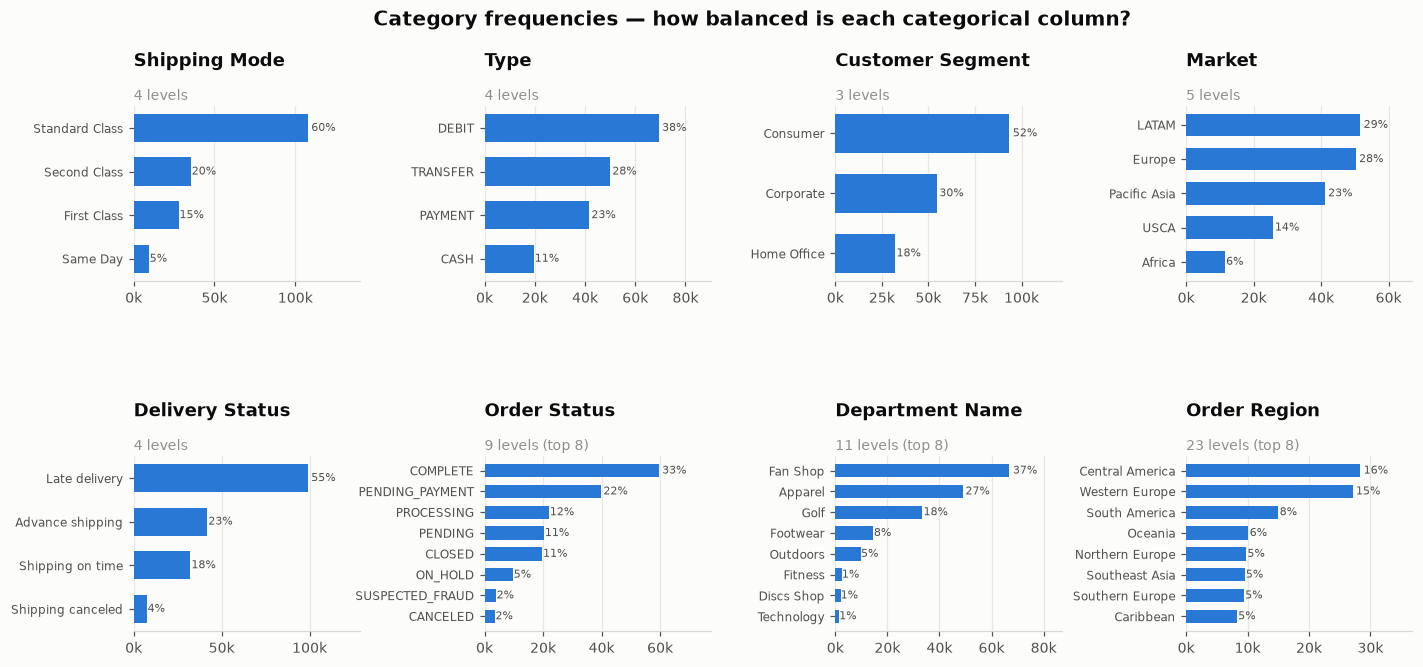

In [11]:
# Frequency of each main categorical column.
# WHY: checks whether any category is so rare that a one-hot column would just
# fit noise. Nothing here is that extreme, so OneHotEncoder with a rare-level
# threshold (min_frequency=20) is sufficient - no manual grouping needed.

# --- Frequency of the main categorical columns -----------------------------
cat_profile = ["Shipping Mode", "Type", "Customer Segment", "Market",
               "Delivery Status", "Order Status", "Department Name", "Order Region"]

fig, axes = plt.subplots(2, 4, figsize=(15, 6.2),
                         gridspec_kw={"hspace": 1.0, "wspace": 0.55})
for ax, col in zip(axes.ravel(), cat_profile):
    vc = raw[col].value_counts().head(8).sort_values()
    y = np.arange(len(vc))
    ax.barh(y, vc.values, color=C_BLUE, height=.65, zorder=3)
    ax.set_yticks(y); ax.set_yticklabels([str(i)[:20] for i in vc.index], fontsize=8)
    for yi, v in zip(y, vc.values):
        ax.text(v*1.02, yi, f"{v/len(raw):.0%}", va="center", fontsize=7.5, color=INK_2)
    ax.set_xlim(0, vc.max()*1.3)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
    nlev = raw[col].nunique()
    finish(ax, f"{col}", f"{nlev} levels" + (" (top 8)" if nlev > 8 else ""), hgrid=True)
fig.suptitle("Category frequencies — how balanced is each categorical column?",
             x=0.5, y=1.02, fontsize=13, fontweight="bold", color=INK)
save(fig, "00e_categorical_frequencies"); plt.show()

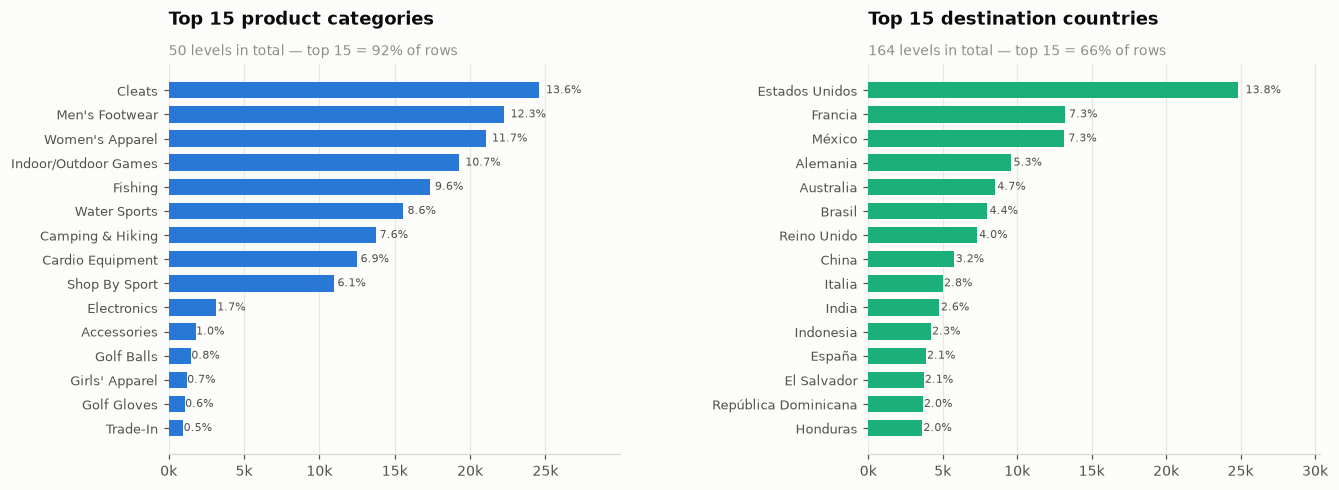

In [12]:
# WHAT IS SOLD, AND WHERE TO - the top of each long tail.
# WHY: Category Name has 50 levels and Order Country 164. Charting the top 15
# shows how concentrated they are, which is what justifies keeping the coarse
# geography (Order Region, 23 levels) and dropping Order City (3,597 levels).
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6), gridspec_kw={"wspace": 0.55})

for ax, col, c_, title in [
        (axes[0], "Category Name",  C_BLUE,  "Top 15 product categories"),
        (axes[1], "Order Country",  C_AQUA,  "Top 15 destination countries")]:
    vc = raw[col].value_counts().head(15).sort_values()
    y = np.arange(len(vc))
    ax.barh(y, vc.values, color=c_, height=.68, zorder=3)
    ax.set_yticks(y); ax.set_yticklabels([str(i)[:26] for i in vc.index], fontsize=8.5)
    for yi, v in zip(y, vc.values):
        ax.text(v * 1.02, yi, f"{v/len(raw):.1%}", va="center", fontsize=7.5, color=INK_2)
    ax.set_xlim(0, vc.max() * 1.22)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
    share = vc.sum() / len(raw)
    finish(ax, title, f"{raw[col].nunique()} levels in total — top 15 = {share:.0%} of rows",
           hgrid=True)

save(fig, "00h_top_categories_countries"); plt.show()

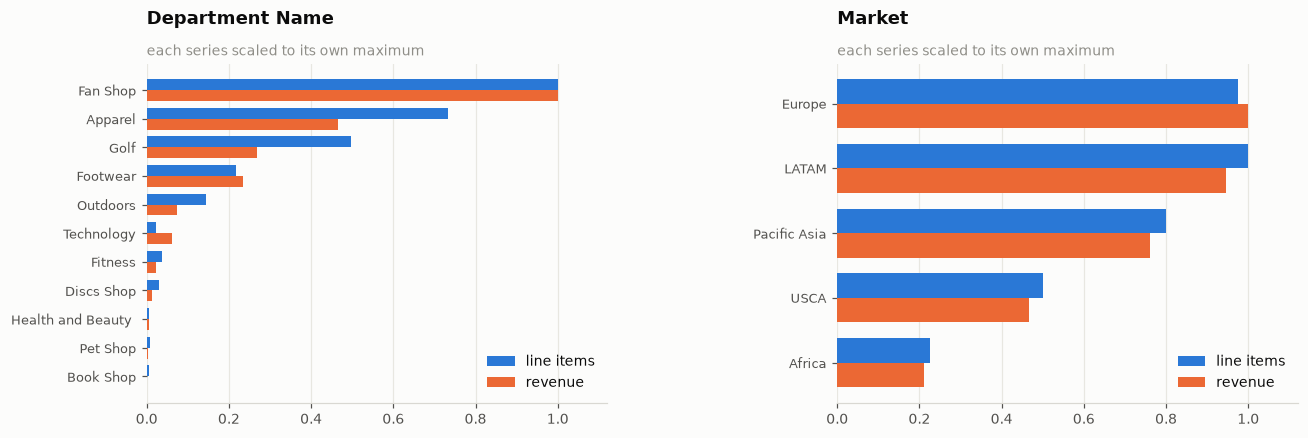

In [13]:
# VOLUME vs REVENUE by department and market.
# WHY both: a department can be high-volume but low-value (or the reverse), and
# that difference is business context the report needs. Still no target used.
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.0), gridspec_kw={"wspace": 0.5})

for ax, col in [(axes[0], "Department Name"), (axes[1], "Market")]:
    g = (raw.groupby(col)
            .agg(rows=("Sales", "size"), revenue=("Sales", "sum"))
            .sort_values("revenue"))
    y = np.arange(len(g)); h = 0.38
    ax.barh(y + h/2, g["rows"] / g["rows"].max(), height=h, color=C_BLUE,
            label="line items", zorder=3)
    ax.barh(y - h/2, g["revenue"] / g["revenue"].max(), height=h, color=C_ORANGE,
            label="revenue", zorder=3)
    ax.set_yticks(y); ax.set_yticklabels(g.index, fontsize=8.5)
    ax.set_xlim(0, 1.12)
    ax.legend(loc="lower right")
    finish(ax, col, "each series scaled to its own maximum", hgrid=True)

save(fig, "00i_volume_vs_revenue"); plt.show()

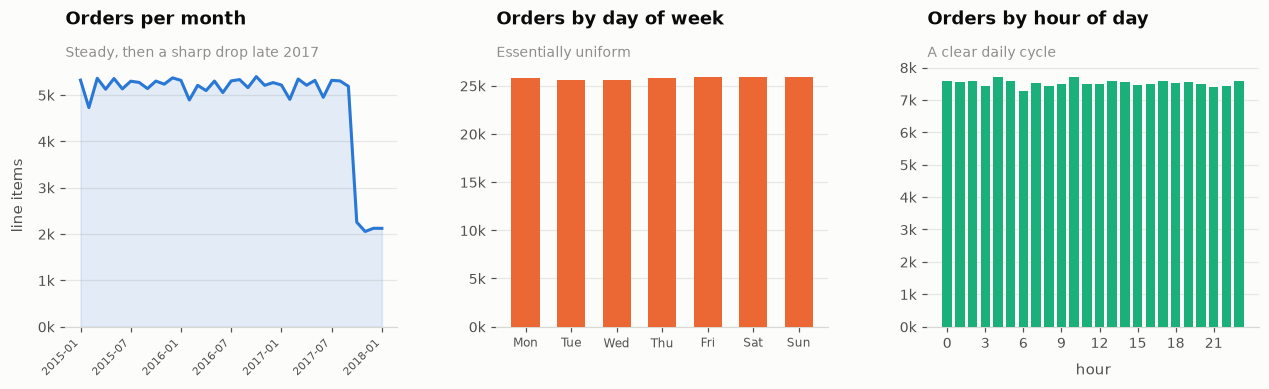

In [14]:
# Order volume over time, by weekday and by hour.
# READ: volume is flat ~5,200/month until Oct 2017 then drops (collection window
# ends) - this informs the split boundaries. Weekday is almost perfectly uniform,
# which is unusual for real retail and hints the timestamps may be synthetic.
# Hour shows a real daily cycle => worth engineering a feature from.

# --- Temporal and cyclical structure of order volume -----------------------
dts = raw["order date (DateOrders)"].dt

fig, axes = plt.subplots(1, 3, figsize=(14, 3.1), gridspec_kw={"wspace": 0.3})

monthly_vol = raw.groupby(dts.to_period("M").astype(str)).size()
ax = axes[0]
ax.plot(range(len(monthly_vol)), monthly_vol.values, color=C_BLUE, linewidth=2, zorder=3)
ax.fill_between(range(len(monthly_vol)), monthly_vol.values, color=C_BLUE, alpha=.12, zorder=2)
step = 6
ax.set_xticks(range(0, len(monthly_vol), step))
ax.set_xticklabels(monthly_vol.index[::step], rotation=45, ha="right", fontsize=7.5)
ax.set_ylim(0)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
finish(ax, "Orders per month", "Steady, then a sharp drop late 2017", ylabel="line items")

dow = raw.groupby(dts.dayofweek).size()
ax = axes[1]
ax.bar(dow.index, dow.values, color=C_ORANGE, width=.62, zorder=3)
ax.set_xticks(range(7)); ax.set_xticklabels(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"], fontsize=8)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
finish(ax, "Orders by day of week", "Essentially uniform")

hr = raw.groupby(dts.hour).size()
ax = axes[2]
ax.bar(hr.index, hr.values, color=C_AQUA, width=.75, zorder=3)
ax.set_xticks(range(0, 24, 3))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
finish(ax, "Orders by hour of day", "A clear daily cycle", xlabel="hour")
save(fig, "00f_temporal_profile"); plt.show()

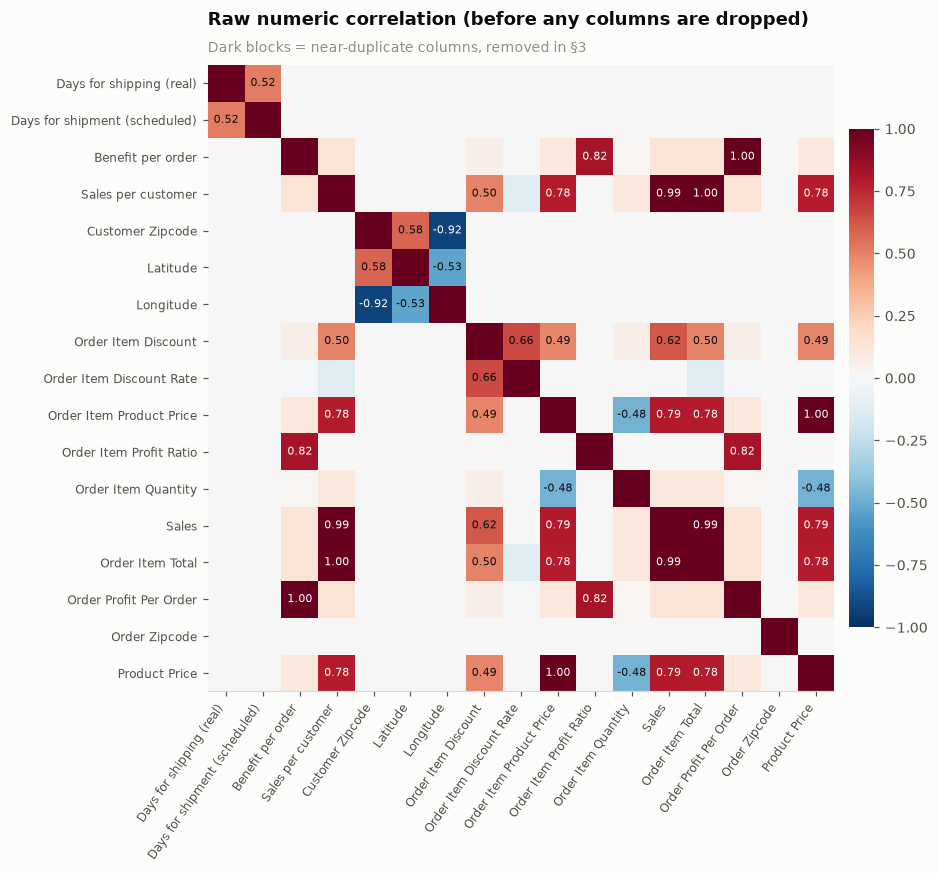

In [15]:
# CORRELATION among the RAW numeric columns, before any are dropped.
# WHY here as well as in 9.6: this version still contains the leakage and
# post-hoc columns, so it shows the blocks of near-duplicates that Section 3
# then removes. Diverging scale, neutral at zero.
num_raw = [c for c in raw.select_dtypes(include=np.number).columns
           if raw[c].nunique() > 2 and "Id" not in c]
cr = raw[num_raw].corr()

fig, ax = plt.subplots(figsize=(8.6, 7.4))
im = ax.imshow(cr.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cr))); ax.set_xticklabels(cr.columns, rotation=55, ha="right", fontsize=8)
ax.set_yticks(range(len(cr))); ax.set_yticklabels(cr.index, fontsize=8)
for i in range(len(cr)):
    for j in range(len(cr)):
        v = cr.to_numpy()[i, j]
        if abs(v) > .45 and i != j:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                    color="#ffffff" if abs(v) > .75 else INK)
ax.grid(False)
finish(ax, "Raw numeric correlation (before any columns are dropped)",
       "Dark blocks = near-duplicate columns, removed in §3")
cb = fig.colorbar(im, ax=ax, fraction=.034, pad=.02); cb.outline.set_visible(False)
save(fig, "00j_raw_correlation"); plt.show()

Dark off-diagonal blocks are the duplicate column groups — confirmed exactly in §3.

---
## 3 · Redundancy audit

In [16]:
# REDUNDANCY CHECK: compare every pair of numeric columns element-wise.
# WHY mechanically: identical columns destabilise a logistic regression
# (coefficients become unidentifiable) and waste capacity in trees.
# Eyeballing 53 columns would miss them. Finds 6 exact duplicate pairs.

num_cols_all = raw.select_dtypes(include=np.number).columns.tolist()

# Find every pair of numeric columns that are element-wise identical.
identical_pairs = []
for i, a in enumerate(num_cols_all):
    for b in num_cols_all[i+1:]:
        if raw[a].equals(raw[b]):
            identical_pairs.append((a, b))

print("Exactly identical numeric column pairs:")
for a, b in identical_pairs:
    print(f"   {a:<32s} == {b}")

# Known derived relationships worth confirming explicitly.
print("\nDerived relationships:")
print("  Sales            == Product Price x Quantity :",
      bool(((raw['Product Price']*raw['Order Item Quantity'] - raw['Sales']).abs() < .01).all()))
print("  Order Item Total == Sales - Discount         :",
      f"{((raw['Sales']-raw['Order Item Discount']-raw['Order Item Total']).abs()<.01).mean():.2%} of rows")

Exactly identical numeric column pairs:
   Benefit per order                == Order Profit Per Order
   Sales per customer               == Order Item Total
   Category Id                      == Product Category Id
   Customer Id                      == Order Customer Id
   Order Item Cardprod Id           == Product Card Id
   Order Item Product Price         == Product Price

Derived relationships:
  Sales            == Product Price x Quantity : True
  Order Item Total == Sales - Discount         : 99.32% of rows


In [17]:
# Is Shipping Mode just Days-for-shipment written twice?
# ANSWER: yes - a perfect 1-to-1 map (Same Day=0, First=1, Second=2, Standard=4).
# WHY it matters: feeding both DOUBLE-COUNTS the strongest predictor. We keep the
# CATEGORICAL form so the model learns a separate effect per mode, rather than
# being forced into a linear trend in "days".

# Shipping Mode and the scheduled-days field: are they the same information twice?
ct = pd.crosstab(raw["Shipping Mode"], raw["Days for shipment (scheduled)"])
print("Shipping Mode  x  Days for shipment (scheduled)\n")
print(ct)
print("\nEach shipping mode maps to exactly one scheduled duration:",
      bool((ct > 0).sum(axis=1).eq(1).all()))

Shipping Mode  x  Days for shipment (scheduled)

Days for shipment (scheduled)     0      1      2       4
Shipping Mode                                            
First Class                       0  27814      0       0
Same Day                       9737      0      0       0
Second Class                      0      0  35216       0
Standard Class                    0      0      0  107752

Each shipping mode maps to exactly one scheduled duration: True


`Shipping Mode` and `Days for shipment (scheduled)` are **1-to-1** — the same variable twice. Keep the categorical form only.

---
## 4 · Leakage audit

In [18]:
# LEAKAGE AUDIT - the single most important cell in this notebook.
# TEST: is the label simply (real shipping days > scheduled days)?
# RESULT: reproduces the label on 97.55% of rows => YES.
# WHY this matters: Days for shipping (real) is only known AFTER the order ships,
# so it cannot be an input. Delivery Status is the same answer written in words.
# Leaving them in would score ~100% for the wrong reason.
# The 2.45% that disagree are ALL "Shipping canceled" rows -> handled next.

derived = (raw["Days for shipping (real)"] > raw["Days for shipment (scheduled)"]).astype(int)
match   = (derived == raw[TARGET])

print(f"Rule 'real > scheduled' reproduces the label on {match.mean():.4%} of rows\n")
print("Where the rule disagrees with the label, what is the Delivery Status?")
print(raw.loc[~match, "Delivery Status"].value_counts().to_string())

print("\n\nDelivery Status  x  Late_delivery_risk")
print(pd.crosstab(raw["Delivery Status"], raw[TARGET]))

Rule 'real > scheduled' reproduces the label on 97.5498% of rows

Where the rule disagrees with the label, what is the Delivery Status?
Delivery Status
Shipping canceled    4423


Delivery Status  x  Late_delivery_risk
Late_delivery_risk      0      1
Delivery Status                 
Advance shipping    41592      0
Late delivery           0  98977
Shipping canceled    7754      0
Shipping on time    32196      0


Confirmed: the label is `real days > scheduled days` (97.55% match). Dropped as leakage —
`Days for shipping (real)`, `Delivery Status`, `shipping date (DateOrders)`, `Order Status`.
All are post-shipment, so unknowable at order time. Keeping them would score ~100%.

---
## 5 · Scope filter

In [19]:
# SCOPE FILTER: remove orders that never shipped.
# WHY: "delivered late" is UNDEFINED for a cancelled order. Their label of 0 does
# not mean "on time", it means "not applicable" - so keeping them would teach the
# model that cancelled = on time, which is false.
# Cross-check first: CANCELED+SUSPECTED_FRAUD coincide EXACTLY with
# Delivery Status == "Shipping canceled" (7,754 rows, 4.3%).
# Balance rises 54.8% -> 57.3% late, because every removed row was labelled 0.

CANCEL_STATUSES = ["CANCELED", "SUSPECTED_FRAUD"]

is_cancelled = raw["Order Status"].isin(CANCEL_STATUSES)
print("Order Status breakdown\n", raw["Order Status"].value_counts().to_string(), sep="")
print("\nCross-check: Order Status in {CANCELED, SUSPECTED_FRAUD}  x  Delivery Status")
print(pd.crosstab(is_cancelled, raw["Delivery Status"]))

df = raw.loc[~is_cancelled].copy().reset_index(drop=True)
print(f"\nRemoved {is_cancelled.sum():,} cancelled / suspected-fraud rows "
      f"({is_cancelled.mean():.2%} of the data)")
print(f"Rows remaining: {df.shape[0]:,}")
print(f"Class balance after filtering:\n{df[TARGET].value_counts(normalize=True).round(4).to_string()}")

Order Status breakdown
Order Status
COMPLETE           59491
PENDING_PAYMENT    39832
PROCESSING         21902
PENDING            20227
CLOSED             19616
ON_HOLD             9804
SUSPECTED_FRAUD     4062
CANCELED            3692
PAYMENT_REVIEW      1893

Cross-check: Order Status in {CANCELED, SUSPECTED_FRAUD}  x  Delivery Status
Delivery Status  Advance shipping  Late delivery  Shipping canceled  Shipping on time
Order Status                                                                         
False                       41592          98977                  0             32196
True                            0              0               7754                 0

Removed 7,754 cancelled / suspected-fraud rows (4.30% of the data)
Rows remaining: 172,765
Class balance after filtering:
Late_delivery_risk
1    0.5729
0    0.4271


Cancelled / fraud orders never shipped, so "late" is undefined for them. Balance becomes **57.3% late** — mild, so no resampling; accuracy alone is invalid.

---
## 6 · Feature engineering

In [20]:
# FEATURE ENGINEERING from the order timestamp.
# WHY: the raw timestamp has 65k unique values and nothing in the test period was
# ever seen in training - useless directly. Its CALENDAR STRUCTURE is reusable.
#
# is_afternoon is the one piece of real feature engineering here. Late rate is
# 54.2% before noon and 60.6% after - a STEP, not a trend (a midday dispatch
# cut-off). A raw hour number fits a straight line through a step and captures
# only part of it; one binary flag encodes the mechanism exactly.
#
# order_year is built but EXCLUDED as a feature: train is 2015-16 and test is
# 2017-18, so the year is always outside the training range at prediction time.
# That is extrapolation, not learning. It is used only to build the splits.

ORDER_DT = "order date (DateOrders)"
d = df[ORDER_DT].dt

df["order_year"]      = d.year          # used ONLY for splitting, never as a feature (see below)
df["order_month"]     = d.month
df["order_day"]       = d.day
df["order_dayofweek"] = d.dayofweek     # Monday = 0
df["order_hour"]      = d.hour
df["order_quarter"]   = d.quarter
df["order_weekofyear"]= d.isocalendar().week.astype(int)
df["is_weekend"]      = (d.dayofweek >= 5).astype(int)
df["is_month_end"]    = d.is_month_end.astype(int)
df["is_quarter_end"]  = d.is_quarter_end.astype(int)

# Orders placed from 12:00 onward are late markedly more often -- a midday dispatch
# cut-off. The effect is a STEP, not a trend, so a raw hour number models it badly.
# Justified empirically in Section 9.10; see the note below.
df["is_afternoon"]    = (d.hour >= 12).astype(int)

ENGINEERED = ["order_month", "order_day", "order_dayofweek", "order_hour", "order_quarter",
              "order_weekofyear", "is_weekend", "is_month_end", "is_quarter_end",
              "is_afternoon"]

df[[ORDER_DT] + ENGINEERED].head()

,order date (DateOrders),order_month,order_day,order_dayofweek,order_hour,order_quarter,order_weekofyear,is_weekend,is_month_end,is_quarter_end,is_afternoon
0,2018-01-31 22:56:00,1,31,2,22,1,5,0,1,0,1
1,2018-01-13 12:27:00,1,13,5,12,1,2,1,0,0,1
2,2018-01-13 12:06:00,1,13,5,12,1,2,1,0,0,1
3,2018-01-13 11:45:00,1,13,5,11,1,2,1,0,0,0
4,2018-01-13 11:24:00,1,13,5,11,1,2,1,0,0,0


`is_afternoon`: late rate jumps 54.2% → 60.6% at noon — a **step**, not a trend (midday dispatch cut-off).
`order_year` excluded — train is 2015–16 and test 2017–18, so year is always out of range at prediction time.

---
## 7 · Column decision log

All 53 columns bucketed with a reason; the cell asserts the buckets partition the list.

In [21]:
# DECISION LOG: assign all 53 original columns to exactly one bucket with a
# written reason - leakage / no-information / identifier / pii / sparse /
# redundant / post-hoc / high-cardinality - then define the kept feature set.
#
# WHY the asserts at the bottom: they prove the buckets PARTITION the column
# list, so a column can never be silently forgotten or kept in two places.
# If a column is ever added or renamed, this cell fails loudly instead of
# quietly letting something through.

DROP_REASONS = {
    # --- Target leakage: unknowable at order time, encodes the answer -------
    "Days for shipping (real)":      ("leakage", "Actual shipping duration; the label is literally derived from it"),
    "Delivery Status":               ("leakage", "The target restated in words (Late / On time / Advance)"),
    "shipping date (DateOrders)":    ("leakage", "Actual dispatch timestamp; post-order information"),
    "Order Status":                  ("leakage", "Post-order lifecycle state; not available at prediction time"),

    # --- Constant / empty: zero information ---------------------------------
    "Product Description":           ("no-information", "100% null"),
    "Customer Email":                ("no-information", "Single masked value for every row"),
    "Customer Password":             ("no-information", "Single masked value for every row"),
    "Product Status":                ("no-information", "Constant 0 (every product in stock)"),

    # --- Identifiers & personal data: no generalisable signal, PII risk ------
    "Order Item Id":                 ("identifier", "Row primary key"),
    "Order Id":                      ("identifier", "Order key; retained temporarily for split checks"),
    "Customer Id":                   ("identifier", "Customer key"),
    "Order Customer Id":             ("identifier", "Duplicate of Customer Id"),
    "Product Card Id":               ("identifier", "Product key; Category Name carries the meaning"),
    "Order Item Cardprod Id":        ("identifier", "Duplicate of Product Card Id"),
    "Category Id":                   ("identifier", "Numeric code for Category Name"),
    "Product Category Id":           ("identifier", "Duplicate of Category Id"),
    "Department Id":                 ("identifier", "Numeric code for Department Name"),
    "Customer Fname":                ("pii", "Personal data; no predictive value"),
    "Customer Lname":                ("pii", "Personal data; no predictive value"),
    "Customer Street":               ("pii", "Personal address; 7,458 distinct values"),
    "Customer Zipcode":              ("pii", "Personal address; location captured by Lat/Long and State"),

    # --- Sparse / non-informative -------------------------------------------
    "Order Zipcode":                 ("sparse", "86% missing; destination captured by Order Region"),
    "Product Image":                 ("no-information", "Static image URL, one per product"),

    # --- Redundant: exact duplicate or exact alias of a kept column ----------
    "Sales per customer":            ("redundant", "Identical to Order Item Total"),
    "Order Item Product Price":      ("redundant", "Identical to Product Price"),
    "Order Profit Per Order":        ("redundant", "Identical to Benefit per order"),
    "Sales":                         ("redundant", "Exactly Product Price x Order Item Quantity"),
    "Days for shipment (scheduled)": ("redundant", "1-to-1 alias of Shipping Mode; kept in categorical form"),
    "Product Name":                  ("redundant", "118 levels nested inside Category Name (50 levels)"),

    # --- Outcome-side financials: realised after the sale --------------------
    "Benefit per order":             ("post-hoc", "Realised profit; an accounting outcome, not an order input"),
    "Order Item Profit Ratio":       ("post-hoc", "Realised profit margin; same objection"),

    # --- High-cardinality geography: superseded by coarser kept columns ------
    "Customer City":                 ("high-cardinality", "563 levels; store location kept via Lat/Long + State"),
    "Order City":                    ("high-cardinality", "3,597 levels; destination kept via Order Region"),
    "Order State":                   ("high-cardinality", "1,089 levels; destination kept via Order Region"),
    "Order Country":                 ("high-cardinality", "164 levels; nested inside Order Region (23 levels)"),
}

# --- The feature set we keep ------------------------------------------------
CAT_FEATURES = [
    "Type",                  # transaction type: DEBIT / TRANSFER / CASH / PAYMENT
    "Shipping Mode",         # Standard / First / Second / Same Day -- the service level promised
    "Customer Segment",      # Consumer / Corporate / Home Office
    "Customer Country",      # store country (2 levels)
    "Customer State",        # store state (46 levels)
    "Market",                # destination market (5 levels)
    "Order Region",          # destination region (23 levels)
    "Department Name",       # 11 levels
    "Category Name",         # 50 levels
]

NUM_FEATURES = [
    "Order Item Quantity",
    "Order Item Discount",
    "Order Item Discount Rate",
    "Product Price",
    "Order Item Total",
    "Latitude", "Longitude",  # store coordinates
] + ENGINEERED

FEATURES = CAT_FEATURES + NUM_FEATURES

# --- Integrity check: the buckets must partition the original 53 columns ----
kept_original    = set(CAT_FEATURES + NUM_FEATURES) - set(ENGINEERED)
dropped_original = set(DROP_REASONS)
accounted        = kept_original | dropped_original | {TARGET, ORDER_DT}
missing_from_log = set(raw.columns) - accounted
double_counted   = kept_original & dropped_original

assert not missing_from_log, f"Columns with no decision recorded: {missing_from_log}"
assert not double_counted,   f"Columns both kept and dropped: {double_counted}"

print(f"Original columns             : {raw.shape[1]}")
print(f"  target                     : 1  ({TARGET})")
print(f"  order date (split key)     : 1")
print(f"  dropped                    : {len(dropped_original)}")
print(f"  kept as features           : {len(kept_original)}")
print(f"  + engineered from date     : {len(ENGINEERED)}")
print(f"  = final feature count      : {len(FEATURES)}  "
      f"({len(CAT_FEATURES)} categorical, {len(NUM_FEATURES)} numeric)")
print("\nAll 53 columns accounted for.")

Original columns             : 53
  target                     : 1  (Late_delivery_risk)
  order date (split key)     : 1
  dropped                    : 35
  kept as features           : 16
  + engineered from date     : 10
  = final feature count      : 26  (9 categorical, 17 numeric)

All 53 columns accounted for.


In [22]:
# Render the decision log as a table and export it.
# WHY: this CSV goes straight into the report appendix as evidence for the
# "justified handling" rubric criterion.

# Render the decision log as a table (this goes straight into the report appendix).
decision_log = (pd.DataFrame(
        [(c, r, why) for c, (r, why) in DROP_REASONS.items()],
        columns=["column", "reason", "justification"])
    .sort_values(["reason", "column"])
    .reset_index(drop=True))

decision_log.to_csv(ART_DIR / "column_decision_log.csv", index=False)
print(decision_log["reason"].value_counts().to_string(), "\n")
decision_log

reason
identifier          9
redundant           6
no-information      5
high-cardinality    4
leakage             4
pii                 4
post-hoc            2
sparse              1 



,column,reason,justification
0,Customer City,high-cardinality,563 levels; store location kept via Lat/Long +...
1,Order City,high-cardinality,"3,597 levels; destination kept via Order Region"
2,Order Country,high-cardinality,164 levels; nested inside Order Region (23 lev...
3,Order State,high-cardinality,"1,089 levels; destination kept via Order Region"
4,Category Id,identifier,Numeric code for Category Name
5,Customer Id,identifier,Customer key
6,Department Id,identifier,Numeric code for Department Name
7,Order Customer Id,identifier,Duplicate of Customer Id
8,Order Id,identifier,Order key; retained temporarily for split checks
9,Order Item Cardprod Id,identifier,Duplicate of Product Card Id


---
## 8 · Train / validation / test split

Random splitting is wrong here for two reasons: one order spans up to 5 rows sharing a label, and
deployment scores future orders. A chronological split fixes both.

| Split | Period |
|---|---|
| Train | 2015-01-01 → 2016-10-31 |
| Validation | 2016-11-01 → 2017-04-30 |
| Test | 2017-05-01 → 2018-01-31 |

In [23]:
# Is the target STABLE over time? This is the precondition for a temporal split.
# WHY: if the late rate drifted, an out-of-time test set would be a harder (or
# easier) problem than the training set, and the comparison would be unfair.

# --- Is the target stable over time? (the precondition for a temporal split) ---
monthly = (df.set_index(ORDER_DT)
             .groupby(pd.Grouper(freq="MS"))
             .agg(late_rate=(TARGET, "mean"), n_orders=(TARGET, "size")))

print(f"Monthly late-rate range : {monthly['late_rate'].min():.3f} - {monthly['late_rate'].max():.3f}")
print(f"Std. dev. across months : {monthly['late_rate'].std():.4f}  (overall mean {df[TARGET].mean():.3f})")

Monthly late-rate range : 0.552 - 0.593
Std. dev. across months : 0.0098  (overall mean 0.573)


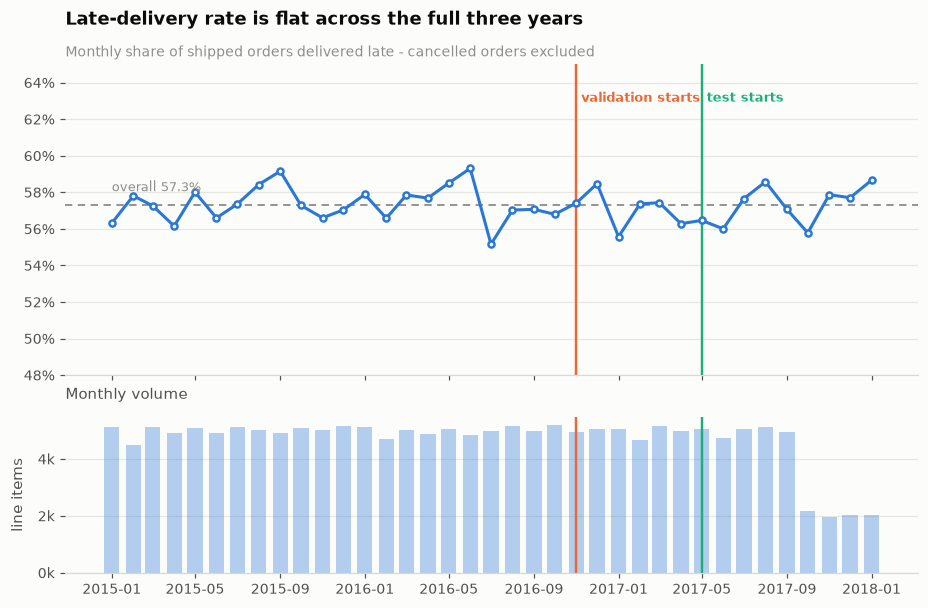

In [24]:
# Plot the monthly late rate with the two split boundaries marked.
# READ: flat across all 37 months, sd ~= 0.01, no trend or seasonality
# => NO concept drift => a chronological split is safe.
# Lower panel: volume drops ~60% from Oct 2017, so the test window is thinner
# but still ~33k rows - enough for stable metrics.

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                         gridspec_kw={"height_ratios": [2, 1], "hspace": 0.18})

ax = axes[0]
ax.plot(monthly.index, monthly["late_rate"], color=C_BLUE, marker="o",
        markersize=4, markerfacecolor=SURFACE, markeredgewidth=1.6, zorder=3)
ax.axhline(df[TARGET].mean(), color=INK_MUTED, linestyle=(0, (4, 3)), linewidth=1.2, zorder=2)
ax.text(monthly.index[0], df[TARGET].mean() + .006,
        f"overall {df[TARGET].mean():.1%}", color=INK_MUTED, fontsize=8.5, va="bottom")
for x, c, lab in [(VAL_START, C_ORANGE, "validation"), (TEST_START, C_AQUA, "test")]:
    ax.axvline(x, color=c, linewidth=1.6, zorder=2)
    ax.text(x, .635, f" {lab} starts", color=c, fontsize=8.5, va="top", fontweight="bold")
ax.set_ylim(0.48, 0.65)
finish(ax, "Late-delivery rate is flat across the full three years",
       "Monthly share of shipped orders delivered late - cancelled orders excluded", pct=True)

ax = axes[1]
ax.bar(monthly.index, monthly["n_orders"], width=22, color=C_BLUE, alpha=.35, linewidth=0)
for x, c in [(VAL_START, C_ORANGE), (TEST_START, C_AQUA)]:
    ax.axvline(x, color=c, linewidth=1.6)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
finish(ax, None, None, ylabel="line items")
ax.set_title("Monthly volume", loc="left", fontsize=9.5, color=INK_2, fontweight="normal")

save(fig, "01_target_stability"); plt.show()

Late rate flat across 37 months (σ ≈ 0.01) → no concept drift, so a temporal split is safe.

In [25]:
# BUILD THE THREE SPLITS by date.
#
# WHY CHRONOLOGICAL instead of random - two independent reasons:
#  (1) GROUPING: one order spans up to 5 rows that SHARE one label. A random row
#      split puts item 1 of an order in train and item 3 in test, answer included.
#      A date split fixes this automatically, because an order has one date.
#  (2) DEPLOYMENT: DataCo would train on history and score future orders. A random
#      split lets the model train on 2017 and test on 2016 - an easier problem
#      than the real one.

# --- Build the three splits -------------------------------------------------
train_mask = df[ORDER_DT] <  VAL_START
val_mask   = (df[ORDER_DT] >= VAL_START) & (df[ORDER_DT] < TEST_START)
test_mask  = df[ORDER_DT] >= TEST_START

train_df = df.loc[train_mask].copy()
val_df   = df.loc[val_mask].copy()
test_df  = df.loc[test_mask].copy()

summary = pd.DataFrame({
    "rows":        [len(train_df), len(val_df), len(test_df)],
    "share":       [len(s)/len(df) for s in (train_df, val_df, test_df)],
    "orders":      [s["Order Id"].nunique() for s in (train_df, val_df, test_df)],
    "first_order": [s[ORDER_DT].min().date() for s in (train_df, val_df, test_df)],
    "last_order":  [s[ORDER_DT].max().date() for s in (train_df, val_df, test_df)],
    "late_rate":   [s[TARGET].mean() for s in (train_df, val_df, test_df)],
}, index=["train", "validation", "test"])
fmt(summary, {"share": ".1%", "late_rate": ".2%", "rows": ",", "orders": ","})

,rows,share,orders,first_order,last_order,late_rate
train,"109,871",63.6%,"36,621",2015-01-01,2016-10-31,57.36%
validation,"29,842",17.3%,"9,928",2016-11-01,2017-04-30,57.09%
test,"33,052",19.1%,"16,348",2017-05-01,2018-01-31,57.25%


In [26]:
# VERIFY the split. These asserts are the evidence that both leak paths are shut.
#  - splits partition the data exactly (no row lost or duplicated)
#  - no Order Id appears in two splits  -> grouping leak closed
#  - splits are strictly ordered in time -> time-travel leak closed
# WHY assert rather than print: a silent leak is worse than a crash.

# --- Verification: the splits must be disjoint in both rows and orders -------
assert len(train_df) + len(val_df) + len(test_df) == len(df), "splits do not partition the data"

o_tr, o_va, o_te = (set(s["Order Id"]) for s in (train_df, val_df, test_df))
assert not (o_tr & o_va), "an order appears in both train and validation"
assert not (o_tr & o_te), "an order appears in both train and test"
assert not (o_va & o_te), "an order appears in both validation and test"
assert train_df[ORDER_DT].max() < val_df[ORDER_DT].min() < val_df[ORDER_DT].max() < test_df[ORDER_DT].min()

print("PASS  splits partition the dataset exactly")
print("PASS  no Order Id is shared between any two splits (grouping leak closed)")
print("PASS  splits are strictly ordered in time (temporal leak closed)")
print(f"\nClass balance drift: train {train_df[TARGET].mean():.2%} | "
      f"val {val_df[TARGET].mean():.2%} | test {test_df[TARGET].mean():.2%}")

PASS  splits partition the dataset exactly
PASS  no Order Id is shared between any two splits (grouping leak closed)
PASS  splits are strictly ordered in time (temporal leak closed)

Class balance drift: train 57.36% | val 57.09% | test 57.25%


---
## 9 · EDA — training set only

In [27]:
# From here on, EDA reads train_df ONLY. val_df and test_df are sealed.
# WHY: EDA is part of model fitting. Any choice made after looking at a chart is
# a choice fitted to the data in that chart. Exploring the full dataset would
# leak test-set structure into our decisions, even without touching a model.

eda = train_df  # single alias so it is obvious nothing else is being read
print(f"EDA sample: {len(eda):,} rows | {eda[ORDER_DT].min():%b %Y} - {eda[ORDER_DT].max():%b %Y}")

EDA sample: 109,871 rows | Jan 2015 - Oct 2016


### 9.1 · Target balance

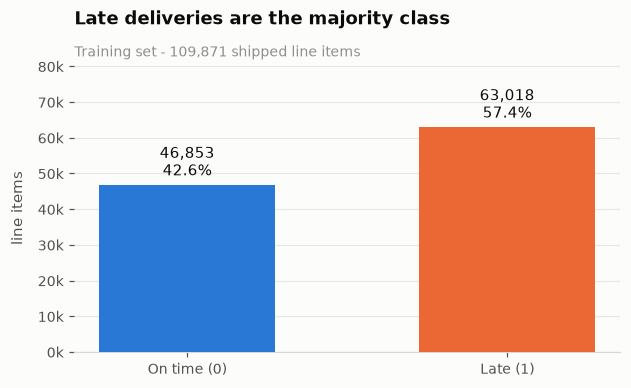

Imbalance ratio 1.35 : 1  -> mild; no resampling required.
A majority-class baseline would score 57.36% accuracy.


In [28]:
# Target balance on the training set.
# READ: 57% late is a MAJORITY class, not a rare event. Two consequences:
#  (1) no SMOTE / resampling needed - it would only distort probabilities;
#  (2) ACCURACY IS INVALID as a headline metric, because always predicting
#      "late" already scores 57%. We report precision/recall/F1/ROC-AUC instead.

counts = eda[TARGET].value_counts().sort_index()
labels = ["On time (0)", "Late (1)"]

fig, ax = plt.subplots(figsize=(6.4, 3.4))
bars = ax.bar(labels, counts.values, color=[C_BLUE, C_ORANGE], width=.55, zorder=3)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width()/2, v + counts.max()*.02, f"{v:,}\n{v/counts.sum():.1%}",
            ha="center", va="bottom", fontsize=9.5, color=INK)
ax.set_ylim(0, counts.max() * 1.28)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
finish(ax, "Late deliveries are the majority class",
       f"Training set - {len(eda):,} shipped line items", ylabel="line items")
save(fig, "02_class_balance"); plt.show()

print(f"Imbalance ratio {counts.max()/counts.min():.2f} : 1  -> mild; no resampling required.")
print(f"A majority-class baseline would score {counts.max()/counts.sum():.2%} accuracy.")

### 9.2 · Late rate by category

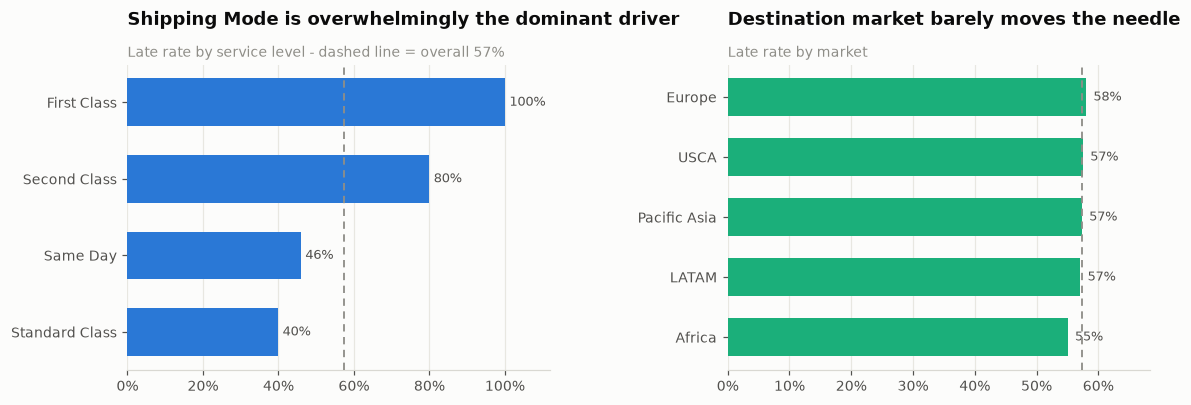

,late_rate,n,lift
Shipping Mode,,,
First Class,100.00%,"16,948",1.74
Second Class,79.94%,"21,565",1.39
Same Day,45.92%,"5,945",0.80
Standard Class,39.90%,"65,413",0.70


In [29]:
# Helper functions for late-rate-by-category charts, then the key comparison.
#
# THE HEADLINE FINDING: Shipping Mode splits the outcome almost completely -
# First Class 100.0% late, Second 79.9%, Same Day 45.9%, Standard 39.9%.
# This is NOT leakage: the customer chooses the mode at checkout, so it is known
# at prediction time. It is a deterministic business rule inside the data.
# Market, by contrast, is flat (55-58%) - geography does not predict lateness.

def late_rate_by(col, data=None):
    data = eda if data is None else data
    return (data.groupby(col, observed=True)[TARGET]
                .agg(late_rate="mean", n="size")
                .sort_values("late_rate", ascending=False))

def plot_rate(ax, g, title, subtitle, base, max_label=30, color=C_BLUE):
    y = np.arange(len(g))[::-1]
    ax.barh(y, g["late_rate"], color=color, height=.62, zorder=3)
    ax.axvline(base, color=INK_MUTED, linestyle=(0, (4, 3)), linewidth=1.2, zorder=4)
    ax.set_yticks(y); ax.set_yticklabels([str(i)[:max_label] for i in g.index])
    for yi, (r, n) in zip(y, g[["late_rate", "n"]].values):
        ax.text(r + .012, yi, f"{r:.0%}", va="center", fontsize=8.8, color=INK_2)
    ax.set_xlim(0, min(1.12, g["late_rate"].max() * 1.18))
    finish(ax, title, subtitle, pct=True, hgrid=True)
    return ax

base = eda[TARGET].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"wspace": 0.42})
plot_rate(axes[0], late_rate_by("Shipping Mode"),
          "Shipping Mode is overwhelmingly the dominant driver",
          f"Late rate by service level - dashed line = overall {base:.0%}", base)
plot_rate(axes[1], late_rate_by("Market"),
          "Destination market barely moves the needle",
          "Late rate by market", base, color=C_AQUA)
save(fig, "03_shipmode_market"); plt.show()

fmt(late_rate_by("Shipping Mode").assign(lift=lambda t: t["late_rate"] / base),
    {"late_rate": ".2%", "n": ",", "lift": ".2f"})

**Key finding — `Shipping Mode` dominates:**

| Mode | Promised | Late rate |
|---|---|---|
| First Class | 1 d | **100.0%** |
| Second Class | 2 d | 79.9% |
| Same Day | 0 d | 45.9% |
| Standard Class | 4 d | 39.9% |

Not leakage — the customer picks the mode at checkout. Expect a performance ceiling around 0.75.

#### Delay mechanism *(only cell that touches leakage columns — for explanation, not modelling)*

                promised  actual_median  actual_min  actual_max  late_rate
Shipping Mode                                                             
First Class            1            2.0           2           2   1.000000
Second Class           2            4.0           2           6   0.799444
Same Day               0            0.0           0           1   0.459209
Standard Class         4            4.0           2           6   0.399003 



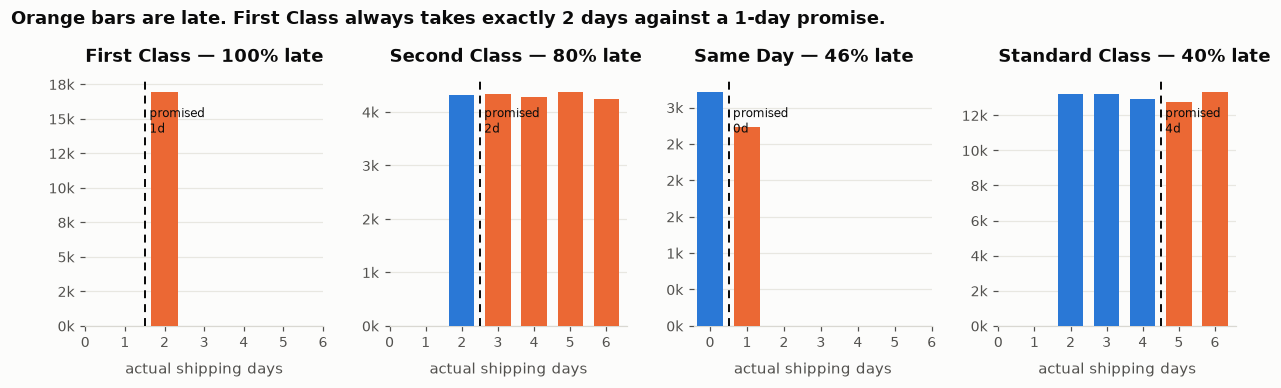

In [30]:
# DIAGNOSTIC ONLY - the one cell that touches the leakage columns.
# WHY that is allowed: we are EXPLAINING the label, not feeding it to a model.
# Understanding why the target behaves as it does is data understanding; it
# becomes leakage only if the column reaches an estimator. It never does.
#
# READ: First Class always takes EXACTLY 2 days against a 1-day promise - zero
# variance, 16,948 of 16,948. And Second Class and Standard Class have IDENTICAL
# actual transit times (2-6 days, median 4) yet are 80% vs 40% late.
# => Lateness is manufactured by the SLA, not by the logistics network.
# This is the evidence behind the final recommendation.

# DIAGNOSTIC ONLY -- these columns are dropped from the feature set (Section 7).
mech = (eda.groupby("Shipping Mode")
           .agg(promised=("Days for shipment (scheduled)", "first"),
                actual_median=("Days for shipping (real)", "median"),
                actual_min=("Days for shipping (real)", "min"),
                actual_max=("Days for shipping (real)", "max"),
                late_rate=(TARGET, "mean"))
           .sort_values("late_rate", ascending=False))
print(mech.to_string(), "\n")

fig, axes = plt.subplots(1, 4, figsize=(13.5, 2.9), gridspec_kw={"wspace": 0.28})
for ax, (mode, row) in zip(axes, mech.iterrows()):
    sub = eda.loc[eda["Shipping Mode"] == mode, "Days for shipping (real)"]
    vals = sub.value_counts().sort_index()
    cols = [C_ORANGE if v > row["promised"] else C_BLUE for v in vals.index]
    ax.bar(vals.index, vals.values, color=cols, width=.7, zorder=3)
    ax.axvline(row["promised"] + .5, color=INK, linestyle=(0, (4, 3)), linewidth=1.3, zorder=4)
    ax.text(row["promised"] + .62, vals.max()*.94, f"promised\n{int(row['promised'])}d",
            fontsize=8, color=INK, va="top")
    ax.set_xticks(range(0, 7))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
    finish(ax, f"{mode} — {row['late_rate']:.0%} late", None, xlabel="actual shipping days")
fig.suptitle("Orange bars are late. First Class always takes exactly 2 days against a 1-day promise.",
             x=0.075, y=1.10, ha="left", fontsize=12, fontweight="bold", color=INK)
save(fig, "03b_delay_mechanism"); plt.show()

Second Class and Standard Class have **identical actual transit times** (2–6 d, median 4) yet are 80% vs 40% late. Lateness is manufactured by the SLA, not the network.

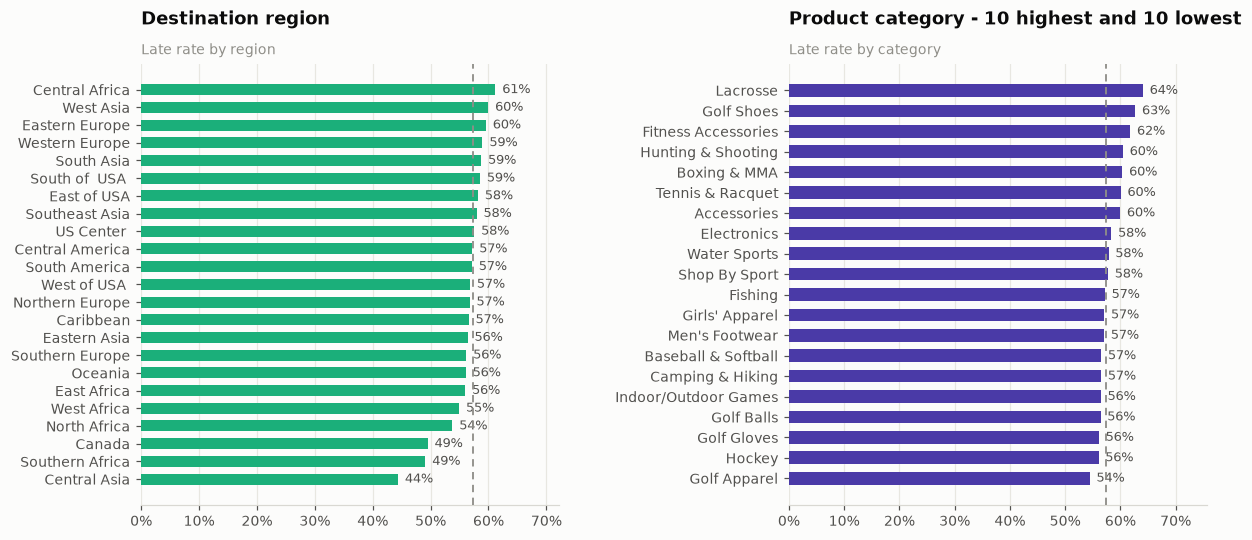

In [31]:
# Late rate by destination region, and by product category (top/bottom 10).
# READ: both hover within a few points of the 57% baseline. The extremes are
# low-volume categories, so the apparent effect is sampling noise, not signal.

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2), gridspec_kw={"wspace": 0.55})
plot_rate(axes[0], late_rate_by("Order Region"),
          "Destination region", "Late rate by region", base, color=C_AQUA)
cat = late_rate_by("Category Name")
plot_rate(axes[1], pd.concat([cat.head(10), cat.tail(10)]),
          "Product category - 10 highest and 10 lowest",
          "Late rate by category", base, color=C_VIOLET)
save(fig, "04_region_category"); plt.show()

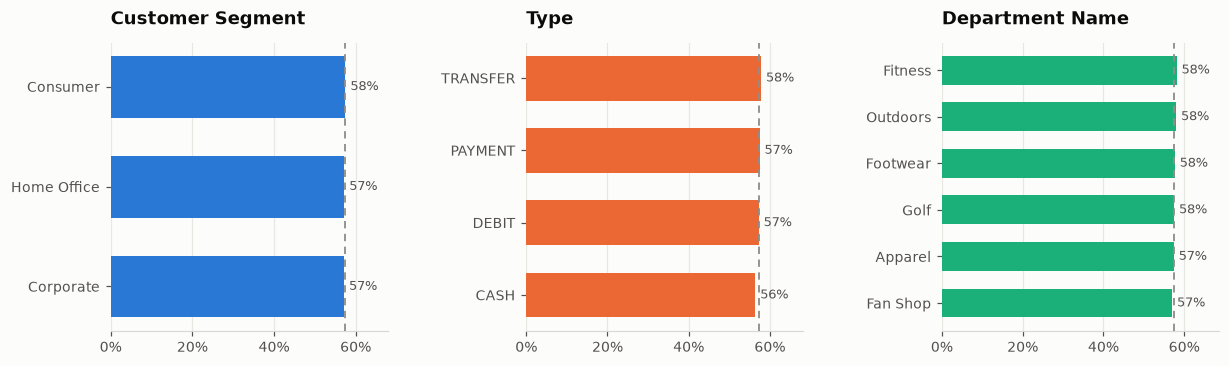

In [32]:
# Late rate by customer segment, transaction type and department.
# READ: all flat. Confirms the signal is concentrated in Shipping Mode. We keep
# these features anyway - trees ignore what is uninformative - but we should not
# expect them to contribute, and the report says so.

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), gridspec_kw={"wspace": 0.5})
for ax, col, c in zip(axes, ["Customer Segment", "Type", "Department Name"],
                      [C_BLUE, C_ORANGE, C_AQUA]):
    plot_rate(ax, late_rate_by(col), col, None, base, color=c)
save(fig, "05_segment_type_dept"); plt.show()

### 9.3 · Mode × Market

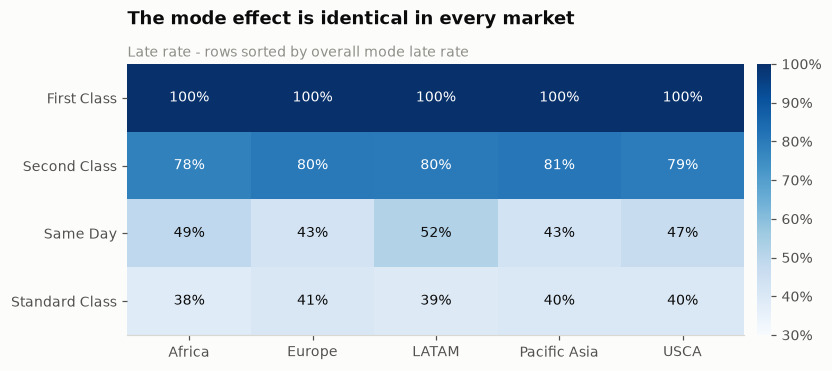

In [33]:
# Does the mode effect DEPEND on destination? (interaction check)
# READ: every row is flat - First Class fails 95-100% whether it ships to Africa
# or the USA. No mode x market interaction.
# IMPLICATIONS: (a) a linear model is not badly handicapped vs a tree ensemble
# here; (b) the fix is a GLOBAL SLA correction, not a region-specific one.

pivot = (eda.pivot_table(index="Shipping Mode", columns="Market",
                         values=TARGET, aggfunc="mean")
            .loc[late_rate_by("Shipping Mode").index])

fig, ax = plt.subplots(figsize=(7.6, 3.2))
im = ax.imshow(pivot.values, cmap="Blues", vmin=0.3, vmax=1.0, aspect="auto")
ax.set_xticks(range(pivot.shape[1])); ax.set_xticklabels(pivot.columns)
ax.set_yticks(range(pivot.shape[0])); ax.set_yticklabels(pivot.index)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=9,
                color="#ffffff" if v > .72 else INK)
ax.grid(False)
finish(ax, "The mode effect is identical in every market",
       "Late rate - rows sorted by overall mode late rate")
cb = fig.colorbar(im, ax=ax, fraction=.028, pad=.02)
cb.outline.set_visible(False); cb.ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
save(fig, "06_mode_market_heatmap"); plt.show()

No interaction — the mode effect is the same everywhere, so one global SLA fix works.

### 9.4 · Numeric distributions & missing values

In [34]:
# Missing values in the RETAINED feature set (after the Section 7 drops).
# RESULT: zero. The only columns that had gaps were dropped for independent
# reasons. We still keep an imputer in the pipeline to guard unseen data.

miss = train_df[FEATURES].isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
if len(miss):
    fig, ax = plt.subplots(figsize=(7, max(1.8, .34*len(miss))))
    ax.barh(np.arange(len(miss))[::-1], miss.values, color=C_ORANGE, height=.6, zorder=3)
    ax.set_yticks(np.arange(len(miss))[::-1]); ax.set_yticklabels(miss.index)
    finish(ax, "Missing values in the retained feature set", None, pct=True, hgrid=True)
    save(fig, "07_missingness"); plt.show()
else:
    print("No missing values remain in the retained feature set.")
    print("(The only columns that had gaps -- Order Zipcode, Customer Zipcode, Customer Lname --")
    print(" were all dropped in Section 7 for independent reasons.)")
print(f"{train_df[FEATURES].isna().sum().sum()} total missing cells across all features")

No missing values remain in the retained feature set.
(The only columns that had gaps -- Order Zipcode, Customer Zipcode, Customer Lname --
 were all dropped in Section 7 for independent reasons.)
0 total missing cells across all features


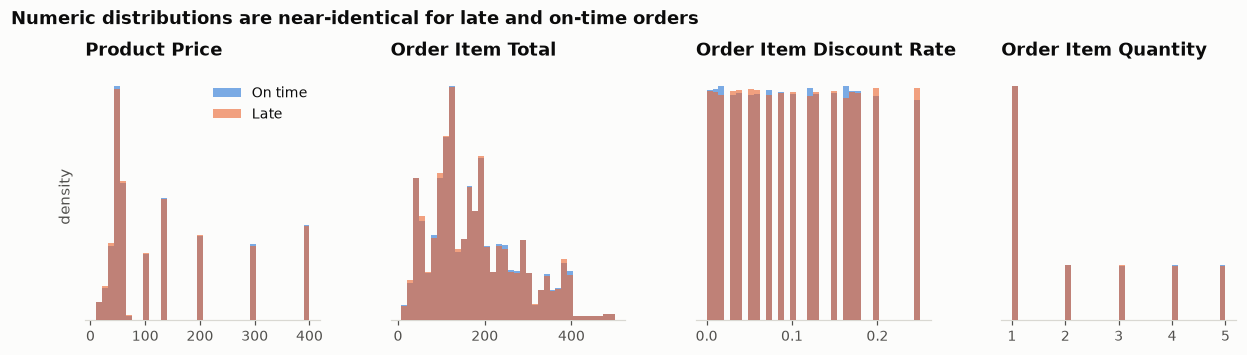

,count,mean,std,min,25%,50%,75%,max
Product Price,109871.0,131.29,117.05,9.99,49.98,59.99,199.99,399.98
Order Item Total,109871.0,176.84,101.16,7.49,103.99,159.99,240.00,499.95
Order Item Discount Rate,109871.0,0.10,0.07,0.00,0.04,0.09,0.16,0.25
Order Item Quantity,109871.0,2.20,1.47,1.00,1.00,1.00,3.00,5.00


In [35]:
# Numeric distributions split by class (late vs on time).
# READ: the two colours sit on top of each other for every money/quantity
# feature. Price and quantity do NOT separate the classes - which makes
# operational sense: a courier is not slower because an item cost more.

show = ["Product Price", "Order Item Total", "Order Item Discount Rate", "Order Item Quantity"]
fig, axes = plt.subplots(1, 4, figsize=(13.5, 2.9), gridspec_kw={"wspace": 0.3})
for ax, col in zip(axes, show):
    for cls, c, lab in [(0, C_BLUE, "On time"), (1, C_ORANGE, "Late")]:
        ax.hist(eda.loc[eda[TARGET] == cls, col], bins=36, color=c, alpha=.62,
                label=lab, zorder=3, density=True, linewidth=0)
    finish(ax, col, None, ylabel="density" if col == show[0] else None)
    ax.set_yticks([])
axes[0].legend(loc="upper right")
fig.suptitle("Numeric distributions are near-identical for late and on-time orders",
             x=0.075, y=1.08, ha="left", fontsize=12, fontweight="bold", color=INK)
save(fig, "08_numeric_distributions"); plt.show()

eda[show].describe().T.round(2)

### 9.5 · Mutual information

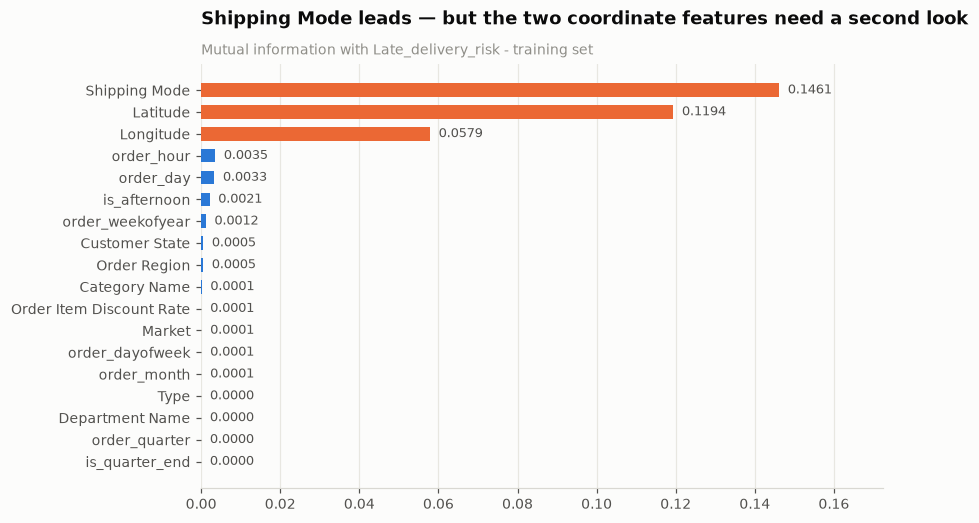

,mutual_information
Shipping Mode,0.14615
Latitude,0.11938
Longitude,0.05787
order_hour,0.00354
order_day,0.00331
is_afternoon,0.00211
order_weekofyear,0.00116
Customer State,0.00051
Order Region,0.00050
Category Name,0.00013


In [36]:
# Rank every feature by MUTUAL INFORMATION with the target.
# WHY MI and not correlation: MI captures non-linear dependence too, and works
# for categorical and numeric features on one common scale.
#
# CAUTION (likely viva question): Latitude ranks 2nd and Longitude 3rd, but
# Section 9.6 shows both have |r| ~ 0.00 with the target. This is an ESTIMATOR
# ARTEFACT - mutual_info_classif uses a k-nearest-neighbour estimator that is
# biased upward for continuous features with many distinct values (Latitude has
# 11,250). Section 11 disproves it with two other methods. This is exactly why
# feature selection should never rest on a single filter.

# Mutual information: captures linear AND non-linear dependence, on one common scale.
mi_frame = eda[FEATURES].copy()
for c in CAT_FEATURES:
    mi_frame[c] = mi_frame[c].astype("category").cat.codes
mi_frame = mi_frame.fillna(mi_frame.median(numeric_only=True))

discrete = [c in CAT_FEATURES or mi_frame[c].nunique() < 20 for c in FEATURES]
mi = pd.Series(
    mutual_info_classif(mi_frame, eda[TARGET], discrete_features=discrete,
                        random_state=RANDOM_STATE),
    index=FEATURES).sort_values(ascending=False)

top = mi.head(18)
fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(top))[::-1]
cols = [C_ORANGE if v > top.iloc[0]*.25 else C_BLUE for v in top.values]
ax.barh(y, top.values, color=cols, height=.62, zorder=3)
ax.set_yticks(y); ax.set_yticklabels(top.index)
for yi, v in zip(y, top.values):
    ax.text(v + top.max()*.015, yi, f"{v:.4f}", va="center", fontsize=8.5, color=INK_2)
ax.set_xlim(0, top.max()*1.18)
finish(ax, "Shipping Mode leads — but the two coordinate features need a second look",
       "Mutual information with Late_delivery_risk - training set", hgrid=True)
save(fig, "09_mutual_information"); plt.show()

mi.to_frame("mutual_information").round(5)

`Latitude`/`Longitude` rank 2nd/3rd but have |r| ≈ 0.00 — a kNN-estimator artefact on high-cardinality continuous features. Disproved in §11.

### 9.6 · Numeric correlation

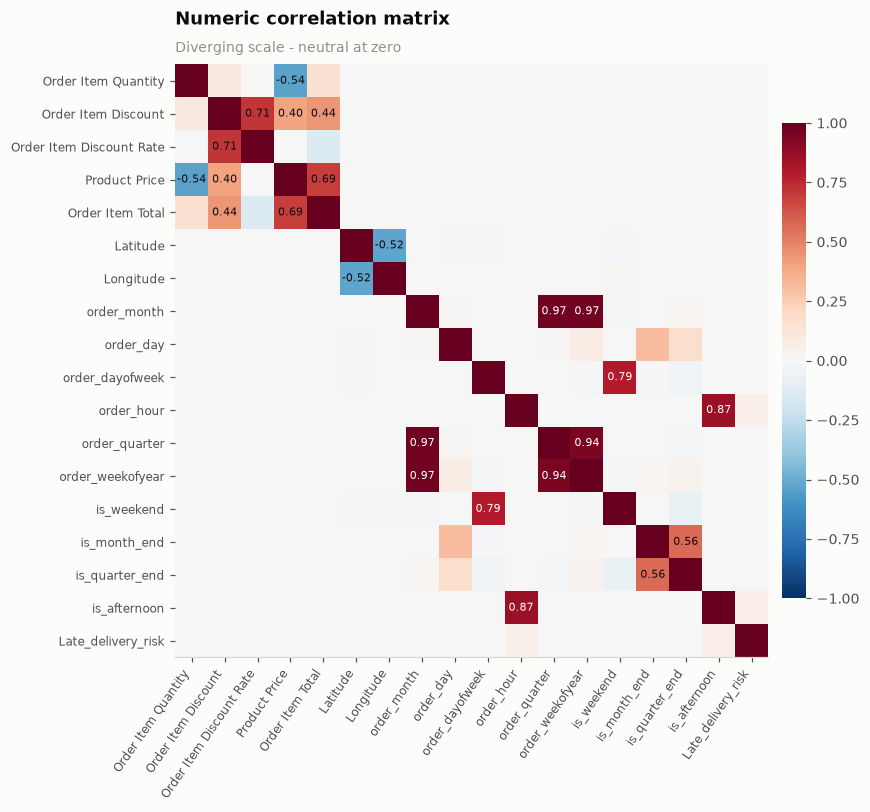

Strongest absolute correlations with the target:
is_afternoon        0.0650
order_hour          0.0513
Order Item Total    0.0056
is_quarter_end      0.0050
is_month_end        0.0046
order_day           0.0038


In [37]:
# Correlation matrix of the numeric features.
# READ: no numeric feature exceeds |r| ~ 0.05 against the target.
# The strong values are BETWEEN features (price drives line total, etc.).

corr = eda[NUM_FEATURES + [TARGET]].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(8.2, 7))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=55, ha="right", fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.values[i, j]
        if abs(v) > .35 and i != j:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                    color="#ffffff" if abs(v) > .72 else INK)
ax.grid(False)
finish(ax, "Numeric correlation matrix", "Diverging scale - neutral at zero")
cb = fig.colorbar(im, ax=ax, fraction=.034, pad=.02); cb.outline.set_visible(False)
save(fig, "10_correlation"); plt.show()

print("Strongest absolute correlations with the target:")
print(corr[TARGET].drop(TARGET).abs().sort_values(ascending=False).head(6).round(4).to_string())

In [38]:
# Verify an EXACT dependency that correlation cannot detect:
#     Order Item Total = Product Price x Order Item Quantity - Order Item Discount
# Holds on 100.00% of rows, yet |r| never exceeds 0.91 - because the relationship
# is MULTIPLICATIVE and Pearson only measures linear association.
# LESSON: a correlation matrix alone will not catch this class of redundancy;
# an explicit identity check will. We keep all four columns deliberately - a tree
# benefits from the precomputed product, and L2 handles the linear model.

# Verify the accounting identity that Pearson correlation cannot see.
identity = (eda["Product Price"] * eda["Order Item Quantity"]
            - eda["Order Item Discount"] - eda["Order Item Total"]).abs()
print(f"Order Item Total == Price x Quantity - Discount : {(identity < 0.02).mean():.4%} of rows")
print(f"  max absolute deviation: {identity.max():.4f}")
print("\n-> An EXACT dependency that |r| never exceeds 0.91, because the relationship")
print("   is multiplicative. Correlation matrices miss this; identity checks do not.")

Order Item Total == Price x Quantity - Discount : 100.0000% of rows
  max absolute deviation: 0.0100

-> An EXACT dependency that |r| never exceeds 0.91, because the relationship
   is multiplicative. Correlation matrices miss this; identity checks do not.


`Order Item Total = Price × Quantity − Discount` on 100% of rows — an exact dependency Pearson cannot see because it is multiplicative.

### 9.7 · Box plots by class

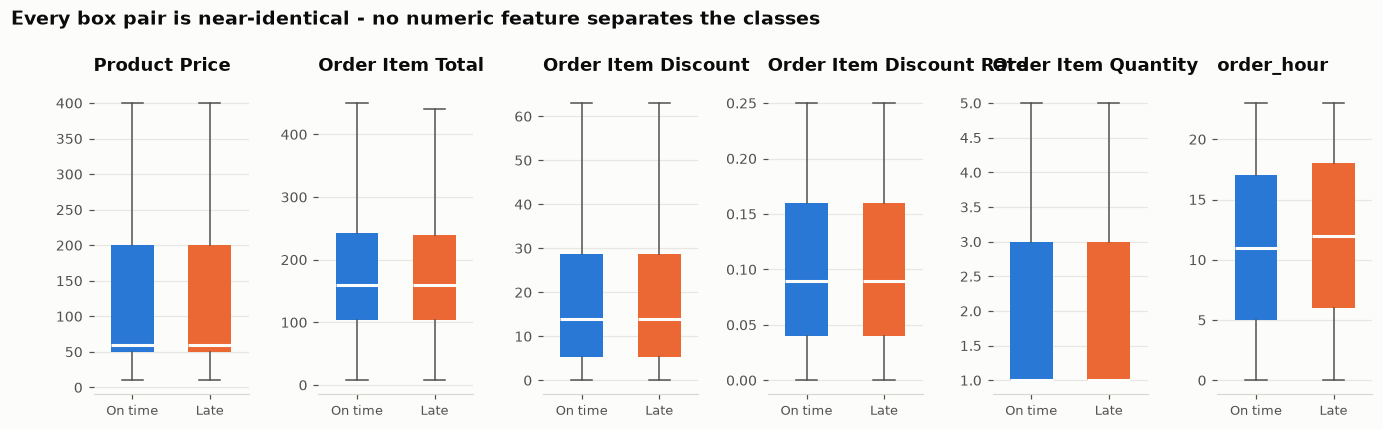

Largest standardised mean differences (Cohen's d) between late and on-time:
is_afternoon                0.1317
order_hour                  0.1040
Order Item Total            0.0113
is_quarter_end              0.0101
is_month_end                0.0093
order_day                   0.0077
order_dayofweek             0.0073
Order Item Discount Rate    0.0066

Rule of thumb: |d| < 0.2 is a negligible effect.


In [39]:
# BOX PLOTS by class, plus Cohen's d (standardised mean difference).
# WHY both: histograms show shape but hide the quartiles; box plots make the
# comparison exact, and Cohen's d puts a number on it.
# READ: every box pair overlaps. Largest effect is order_hour at d=0.104 - below
# the 0.2 "negligible" threshold, but 10x the next feature.
# => the numeric half of the feature set contributes almost nothing.

box_cols = ["Product Price", "Order Item Total", "Order Item Discount",
            "Order Item Discount Rate", "Order Item Quantity", "order_hour"]

fig, axes = plt.subplots(1, 6, figsize=(15, 3.6), gridspec_kw={"wspace": 0.45})
for ax, col in zip(axes, box_cols):
    data = [eda.loc[eda[TARGET] == c, col].dropna().to_numpy() for c in (0, 1)]
    bp = ax.boxplot(data, widths=.55, patch_artist=True, showfliers=False,
                    medianprops=dict(color=SURFACE, linewidth=2),
                    whiskerprops=dict(color=INK_2, linewidth=1),
                    capprops=dict(color=INK_2, linewidth=1))
    for patch, c in zip(bp["boxes"], [C_BLUE, C_ORANGE]):
        patch.set_facecolor(c); patch.set_edgecolor("none")
    ax.set_xticks([1, 2]); ax.set_xticklabels(["On time", "Late"], fontsize=8.5)
    finish(ax, col, None)
fig.suptitle("Every box pair is near-identical - no numeric feature separates the classes",
             x=0.075, y=1.08, ha="left", fontsize=12.5, fontweight="bold", color=INK)
save(fig, "09a_boxplots_by_class"); plt.show()

# Quantify it: standardised mean difference (Cohen's d) per numeric feature.
dmap = {}
for col in NUM_FEATURES:
    a = eda.loc[eda[TARGET] == 0, col].dropna()
    b = eda.loc[eda[TARGET] == 1, col].dropna()
    pooled = np.sqrt((a.var() + b.var()) / 2)
    dmap[col] = (b.mean() - a.mean()) / pooled if pooled > 0 else 0.0
effect = pd.Series(dmap).abs().sort_values(ascending=False)
print("Largest standardised mean differences (Cohen's d) between late and on-time:")
print(effect.head(8).round(4).to_string())
print("\nRule of thumb: |d| < 0.2 is a negligible effect.")

### 9.8 · Order value by shipping mode

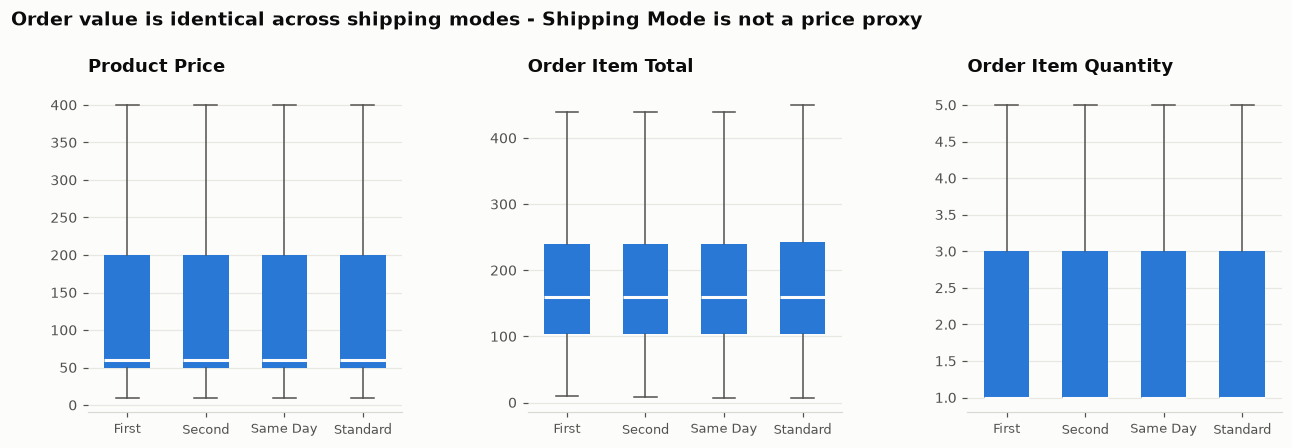

                Product Price  Order Item Total  Order Item Quantity
Shipping Mode                                                       
First Class             59.99            159.96                  1.0
Second Class            59.99            159.99                  1.0
Same Day                59.99            160.00                  1.0
Standard Class          59.99            159.99                  1.0


In [40]:
# CONFOUND CHECK - a fair objection to the Section 9.2 finding:
# "maybe expedited shipping is chosen for expensive orders, and THOSE are late"?
# If so, Shipping Mode would be a proxy for price rather than a cause.
# READ: median order value is IDENTICAL across all four modes. Confound ruled
# out - Shipping Mode predicts lateness on its own merits.

order = late_rate_by("Shipping Mode").index.tolist()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), gridspec_kw={"wspace": 0.4})
for ax, col in zip(axes, ["Product Price", "Order Item Total", "Order Item Quantity"]):
    data = [eda.loc[eda["Shipping Mode"] == m, col].dropna().to_numpy() for m in order]
    bp = ax.boxplot(data, widths=.58, patch_artist=True, showfliers=False,
                    medianprops=dict(color=SURFACE, linewidth=2),
                    whiskerprops=dict(color=INK_2, linewidth=1),
                    capprops=dict(color=INK_2, linewidth=1))
    for patch in bp["boxes"]:
        patch.set_facecolor(C_BLUE); patch.set_edgecolor("none")
    ax.set_xticks(range(1, len(order)+1))
    ax.set_xticklabels([m.replace(" Class", "") for m in order], fontsize=8.5)
    finish(ax, col, None)
fig.suptitle("Order value is identical across shipping modes - Shipping Mode is not a price proxy",
             x=0.075, y=1.07, ha="left", fontsize=12.5, fontweight="bold", color=INK)
save(fig, "09b_value_by_shipmode"); plt.show()

print(eda.groupby("Shipping Mode")[["Product Price", "Order Item Total", "Order Item Quantity"]]
         .median().loc[order].round(2).to_string())

Median order value is identical across modes → `Shipping Mode` is not a proxy for price.

### 9.9 · Categorical association (Cramér's V)

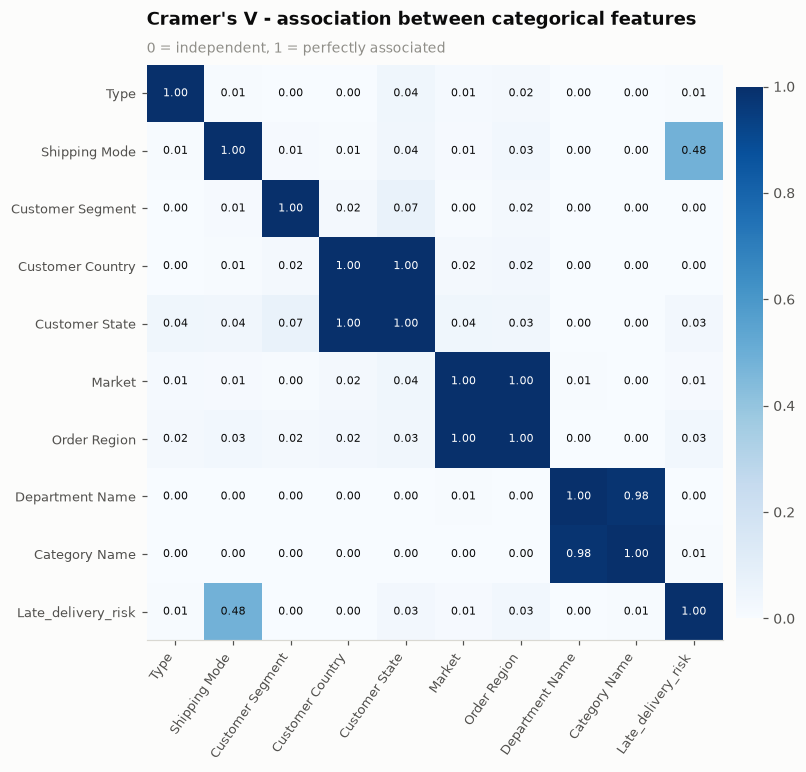

Association with the target:
Shipping Mode       0.4824
Order Region        0.0283
Customer State      0.0250
Market              0.0110
Category Name       0.0063
Type                0.0063
Customer Segment    0.0000
Customer Country    0.0000
Department Name     0.0000


In [41]:
# CRAMER'S V - the correlation matrix for CATEGORICAL variables (0 to 1),
# bias-corrected for table size. Pearson cannot be used on categories.
# TWO results at once:
#  (1) vs target: Shipping Mode 0.48, everything else < 0.03. Same conclusion as
#      mutual information, from a different statistic - and NOT fooled by
#      Latitude, because V only applies to genuine categories.
#  (2) between features: Customer Country<->State = 1.00 and Market<->Order
#      Region = 1.00, i.e. one is COMPLETELY determined by the other. We keep
#      both: the coarse one helps a linear model, the fine one gives trees
#      resolution, and L2 absorbs the overlap (Section 11 confirms it costs
#      0.0002 AUC).

from scipy.stats import chi2_contingency

def cramers_v(a, b):
    """Bias-corrected Cramer's V for two categorical series."""
    ct = pd.crosstab(a, b)
    if ct.shape[0] < 2 or ct.shape[1] < 2:
        return 0.0
    chi2 = chi2_contingency(ct, correction=False)[0]
    n = ct.to_numpy().sum()
    r, k = ct.shape
    phi2 = max(0.0, chi2/n - (k-1)*(r-1)/(n-1))
    rc, kc = r - (r-1)**2/(n-1), k - (k-1)**2/(n-1)
    denom = min(kc-1, rc-1)
    return float(np.sqrt(phi2/denom)) if denom > 0 else 0.0

assoc_cols = CAT_FEATURES + [TARGET]
V = pd.DataFrame(np.eye(len(assoc_cols)), index=assoc_cols, columns=assoc_cols)
for i, a in enumerate(assoc_cols):
    for b in assoc_cols[i+1:]:
        V.loc[a, b] = V.loc[b, a] = cramers_v(eda[a], eda[b])

fig, ax = plt.subplots(figsize=(7.8, 6.8))
im = ax.imshow(V.to_numpy(), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(V))); ax.set_xticklabels(V.columns, rotation=55, ha="right", fontsize=8.5)
ax.set_yticks(range(len(V))); ax.set_yticklabels(V.index, fontsize=8.5)
for i in range(len(V)):
    for j in range(len(V)):
        v = V.to_numpy()[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                color="#ffffff" if v > .55 else INK)
ax.grid(False)
finish(ax, "Cramer's V - association between categorical features",
       "0 = independent, 1 = perfectly associated")
cb = fig.colorbar(im, ax=ax, fraction=.040, pad=.02); cb.outline.set_visible(False)
save(fig, "09c_cramers_v"); plt.show()

print("Association with the target:")
print(V[TARGET].drop(TARGET).sort_values(ascending=False).round(4).to_string())

`Shipping Mode` 0.48 vs target; everything else < 0.03. Three pairs are perfectly nested (V = 1.00) — kept anyway, since L2 absorbs the overlap.

### 9.10 · Delay by calendar position

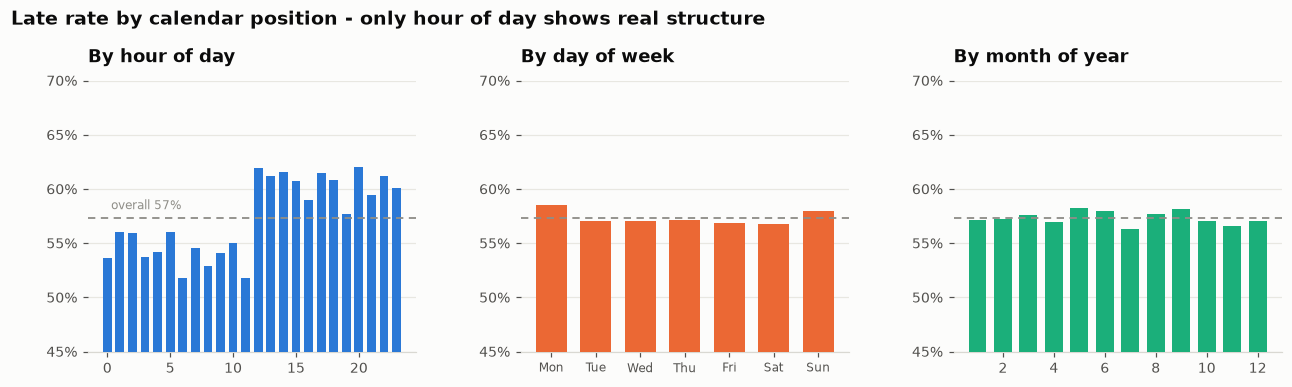

Late rate by hour of day:
  lowest  11:00  51.7%
  highest 20:00  62.0%
  spread  10.3 percentage points


In [42]:
# Late rate by hour, weekday and month (the "when do delays happen?" lens).
# READ: weekday and month are flat - no weekly or seasonal pattern to exploit.
# Hour is the exception: 51.7% at 11:00 rising to 62.0% at 20:00, a 10.3-point
# spread on a smooth curve. Mechanism: evening orders miss the dispatch cut-off
# and lose a day at the depot. This is what is_afternoon encodes.

fig, axes = plt.subplots(1, 3, figsize=(14, 3.2), gridspec_kw={"wspace": 0.32})
base = eda[TARGET].mean()

for ax, (col, labels, title, c) in zip(axes, [
        ("order_hour", None, "By hour of day", C_BLUE),
        ("order_dayofweek", ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"], "By day of week", C_ORANGE),
        ("order_month", None, "By month of year", C_AQUA)]):
    g = eda.groupby(col)[TARGET].mean()
    ax.bar(g.index, g.values, color=c, width=.7, zorder=3)
    ax.axhline(base, color=INK_MUTED, linestyle=(0, (4, 3)), linewidth=1.2, zorder=4)
    if labels:
        ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, fontsize=8)
    ax.set_ylim(0.45, 0.70)
    finish(ax, title, None, pct=True)
axes[0].text(0.3, base + .005, f"overall {base:.0%}", color=INK_MUTED, fontsize=8, va="bottom")
fig.suptitle("Late rate by calendar position - only hour of day shows real structure",
             x=0.075, y=1.08, ha="left", fontsize=12.5, fontweight="bold", color=INK)
save(fig, "09d_delay_by_calendar"); plt.show()

hr = eda.groupby("order_hour")[TARGET].mean()
print("Late rate by hour of day:")
print(f"  lowest  {hr.idxmin():02d}:00  {hr.min():.1%}")
print(f"  highest {hr.idxmax():02d}:00  {hr.max():.1%}")
print(f"  spread  {(hr.max()-hr.min())*100:.1f} percentage points")

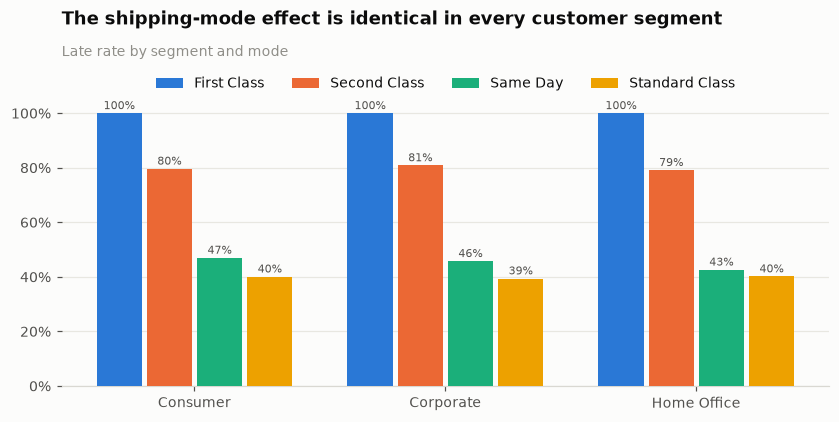

In [43]:
# Does the mode effect hold inside every customer segment?
# READ: identical bar heights and order within Consumer, Corporate and Home
# Office. The mode effect is universal - one global SLA correction fixes it for
# every segment and every market at once.

# Grouped bars: does the mode effect hold inside every customer segment?
seg_order = ["Consumer", "Corporate", "Home Office"]
modes = late_rate_by("Shipping Mode").index.tolist()
pv = eda.pivot_table(index="Customer Segment", columns="Shipping Mode",
                     values=TARGET, aggfunc="mean").loc[seg_order, modes]

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(seg_order)); w = 0.2
for k, (m, c) in enumerate(zip(modes, [C_BLUE, C_ORANGE, C_AQUA, C_YELLOW])):
    vals = pv[m].to_numpy()
    ax.bar(x + (k - 1.5)*w, vals, width=w*0.9, color=c, label=m, zorder=3)
    for xi, v in zip(x + (k - 1.5)*w, vals):
        ax.text(xi, v + .015, f"{v:.0%}", ha="center", fontsize=7.5, color=INK_2)
ax.set_xticks(x); ax.set_xticklabels(seg_order)
ax.set_ylim(0, 1.18); ax.legend(ncol=4, loc="upper center")
finish(ax, "The shipping-mode effect is identical in every customer segment",
       "Late rate by segment and mode", pct=True)
save(fig, "09e_segment_mode_grouped"); plt.show()

---
## 10 · Preprocessing pipeline

`ColumnTransformer` fitted on train only, so it cannot leak and re-fits correctly inside CV.

| Step | Choice |
|---|---|
| Numeric missing | median |
| Numeric scaling | `StandardScaler` |
| Categorical missing | constant `"Missing"` |
| Encoding | `OneHotEncoder`, `min_frequency=20` |
| Unseen levels | `handle_unknown="infrequent_if_exist"` |
| Outliers | kept |
| Imbalance | no resampling |

In [44]:
# THE PREPROCESSING PIPELINE. Built as a ColumnTransformer, not as loose pandas
# statements. Three reasons (common viva question):
#  (1) IT CANNOT LEAK - the imputer's medians, the encoder's category list and
#      the scaler's mean/sd are all learned in .fit() on TRAIN and merely applied
#      elsewhere. Scaling the whole dataset first is the classic mistake.
#  (2) IT IS ONE OBJECT - picklable, so the same transform runs in production.
#  (3) IT IS TUNABLE - it slots in front of any estimator and cross-validates as
#      a unit, so each CV fold is preprocessed correctly too.
#
# Per-step reasoning:
#  median imputation      - robust to the right-skew seen in 9.4
#  StandardScaler         - required by LogReg/KNN; harmless to trees
#  constant "Missing"     - makes absence an explicit, learnable category
#  OneHotEncoder          - all 9 categoricals are NOMINAL (no natural order)
#  handle_unknown=...     - ESSENTIAL under a temporal split; see Section 10.1
#  min_frequency=20       - safety net so a one-hot column cannot fit a handful
#                           of rows. NOTE: on this data it never fires - every
#                           training level already has >=20 rows - so no
#                           "infrequent" bucket is actually created (see 10.1)
#  remainder="drop"       - nothing sneaks in that we did not list explicitly

numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale",  StandardScaler()),
])

categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                             min_frequency=20, sparse_output=False)),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipe,     NUM_FEATURES),
        ("cat", categorical_pipe, CAT_FEATURES),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The

In [45]:
# FIT ON TRAIN ONLY, then TRANSFORM all three splits.
# This ordering is the whole point: .fit() learns the medians, categories and
# scaling constants; .transform() only applies them. Calling .fit_transform() on
# val or test would re-learn them from data the model is not allowed to see.
# 26 raw features expand to 132 encoded columns via one-hot.

# --- Split into X / y -------------------------------------------------------
X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_val,   y_val   = val_df[FEATURES],   val_df[TARGET]
X_test,  y_test  = test_df[FEATURES],  test_df[TARGET]

# --- FIT ON TRAIN ONLY ------------------------------------------------------
preprocessor.fit(X_train)

# --- TRANSFORM all three ----------------------------------------------------
Xt_train = preprocessor.transform(X_train)
Xt_val   = preprocessor.transform(X_val)
Xt_test  = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

print(f"Raw features in  : {len(FEATURES)}  ({len(NUM_FEATURES)} numeric + {len(CAT_FEATURES)} categorical)")
print(f"Encoded features : {Xt_train.shape[1]}")
print()
for name, Xt, y in [("train", Xt_train, y_train), ("validation", Xt_val, y_val),
                    ("test", Xt_test, y_test)]:
    print(f"  {name:<11s} {Xt.shape[0]:>7,} x {Xt.shape[1]:<4d}  late rate {y.mean():.2%}")

Raw features in  : 26  (17 numeric + 9 categorical)
Encoded features : 132

  train       109,871 x 132   late rate 57.36%
  validation   29,842 x 132   late rate 57.09%
  test         33,052 x 132   late rate 57.25%


### 10.1 · Unseen categories

In [46]:
# UNSEEN CATEGORIES - proof that handle_unknown was not defensive boilerplate.
# A chronological split means the encoder is fitted on 2015-16 and must transform
# 2017-18 data, and DataCo's product catalogue EXPANDED over time.
# RESULT: 5 departments and 26 categories exist only in the test period.
# With the default handle_unknown="error", .transform() would raise and the
# notebook would CRASH at the final evaluation.
#
# HOW THEY ARE ACTUALLY ENCODED (likely viva question): because min_frequency
# never fired, there is no "infrequent" bucket to route them to, so an unseen
# level becomes ALL-ZEROS across that feature's one-hot columns - i.e. "none of
# the known categories". That is valid and NaN-free, and the model treats it as
# the reference level. It affects Category Name on 9,139 test rows (28%) and
# Department Name on 4,548 (14%).
# Is that acceptable? Yes here: Cramer's V for Category Name vs the target is
# 0.006, so the feature carries almost no signal to lose. If it had mattered, the
# fix would be target/frequency encoding instead of one-hot.
#
# A random split would have scattered these across all three sets and hidden the
# problem - another reason the chronological split is the right one.

unseen = []
for c in CAT_FEATURES:
    seen = set(X_train[c].dropna().unique())
    nv = set(X_val[c].dropna().unique())  - seen
    nt = set(X_test[c].dropna().unique()) - seen
    if nv or nt:
        unseen.append({"feature": c, "new_in_val": len(nv), "new_in_test": len(nt),
                       "examples": ", ".join(sorted(map(str, nv | nt))[:3])})

if unseen:
    print(pd.DataFrame(unseen).to_string(index=False))
    rows_hit = sum(
        (~X_test[u["feature"]].isin(set(X_train[u["feature"]].dropna().unique()))).sum()
        for u in unseen)
    print(f"\nTest rows touched by at least one unseen level: ~{rows_hit:,}")
else:
    print("No unseen categories.")

print("\nDepartments by year (the catalogue expanded):")
print(pd.crosstab(df["Department Name"], df[ORDER_DT].dt.year).to_string())

        feature  new_in_val  new_in_test                                  examples
 Customer State           0            2                              91732, 95758
Department Name           0            5 Book Shop, Discs Shop, Health and Beauty 
  Category Name           7           26        As Seen on  TV!, Baby , Basketball

Test rows touched by at least one unseen level: ~13,690

Departments by year (the catalogue expanded):
order date (DateOrders)   2015   2016   2017  2018
Department Name                                   
Apparel                  16132  16435  13923   394
Book Shop                    0      0    391     0
Discs Shop                   0      0   1215   728
Fan Shop                 22991  23044  17733   265
Fitness                    736    720    719   199
Footwear                  5225   4945   3721     0
Golf                     11693  11606   8469     0
Health and Beauty            0      0    228   118
Outdoors                  3177   3176   2822    92
Pet

5 departments and 26 categories launched in 2017, so they appear only in test. With the default
`handle_unknown="error"` the final evaluation would crash.

Because `min_frequency` never fires here (every training level already has ≥20 rows), there is no
"infrequent" bucket — an unseen level is encoded as **all-zeros** for that feature, i.e. "none of
the known categories". Valid and NaN-free. It affects `Category Name` on 9,139 test rows (28%) and
`Department Name` on 4,548 (14%); acceptable because Cramér's V for `Category Name` vs the target
is 0.006, so almost no signal is lost.

### 10.2 · Sanity checks

In [47]:
# SANITY CHECKS - six assertions before anything is modelled.
# The second one is the important one: it verifies the TEST block is NOT
# separately standardised. That is POSITIVE PROOF no refit happened, rather than
# just trusting that we wrote the code correctly.

checks = []
n_num = len(NUM_FEATURES)

# 1. The scaler was fitted on train, so the train numeric block is exactly standardised.
ntr = Xt_train[:, :n_num]
checks.append(("Numeric block of train is standardised (mean~0, sd~1)",
               abs(ntr.mean()) < 1e-8 and abs(ntr.std() - 1) < 1e-6))

# 2. Val/test are NOT separately standardised -- positive proof that no refit happened.
nte = Xt_test[:, :n_num]
checks.append(("Test block is NOT separately standardised (no refit leak)",
               abs(nte.mean()) > 1e-6))

# 3. No NaNs or infinities survive.
checks.append(("No NaN / inf in any transformed split",
               all(np.isfinite(X).all() for X in (Xt_train, Xt_val, Xt_test))))

# 4. All three matrices share an identical column space.
checks.append(("Train / val / test have identical column counts",
               Xt_train.shape[1] == Xt_val.shape[1] == Xt_test.shape[1]))

# 5. No constant (zero-variance) column survived encoding.
zero_var = int((Xt_train.std(axis=0) == 0).sum())
checks.append((f"No zero-variance encoded columns (found {zero_var})", zero_var == 0))

# 6. No leakage column leaked into the feature list.
LEAK = {"Days for shipping (real)", "Delivery Status", "shipping date",
        "Order Status", "Days for shipment (scheduled)"}
checks.append(("No leakage column present in the feature matrix",
               not any(any(l in f for l in LEAK) for f in feature_names)))

for label, ok in checks:
    print(f"  {'PASS' if ok else 'FAIL'}  {label}")
assert all(ok for _, ok in checks), "a sanity check failed -- do not proceed to modelling"
print("\nAll sanity checks passed.")

  PASS  Numeric block of train is standardised (mean~0, sd~1)
  PASS  Test block is NOT separately standardised (no refit leak)
  PASS  No NaN / inf in any transformed split
  PASS  Train / val / test have identical column counts
  PASS  No zero-variance encoded columns (found 0)
  PASS  No leakage column present in the feature matrix

All sanity checks passed.


### 10.3 · Leakage smoke test

Expect ~0.70–0.75. Above 0.95 would mean leakage.

In [48]:
# LEAKAGE SMOKE TEST - the decisive check that the leaks are closed.
# We know from Section 9 what a CORRECT result looks like: Shipping Mode carries
# nearly all the signal, so AUC should land around 0.70-0.75.
#   AUC ~0.75  -> pipeline is clean and the problem is genuinely hard
#   AUC >0.95  -> something post-shipment survived; stop and re-audit
# This is a diagnostic, not the modelling step - that is Notebook 2.

dummy = DummyClassifier(strategy="most_frequent").fit(Xt_train, y_train)
logit = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE).fit(Xt_train, y_train)

rows = []
for name, m in [("Majority-class baseline", dummy), ("Logistic Regression (smoke test)", logit)]:
    p     = m.predict(Xt_val)
    proba = m.predict_proba(Xt_val)[:, 1]
    rows.append({"model": name,
                 "accuracy": accuracy_score(y_val, p),
                 "f1":       f1_score(y_val, p, zero_division=0),
                 "roc_auc":  roc_auc_score(y_val, proba)})
res = pd.DataFrame(rows).set_index("model")
print(res.round(4).to_string())

auc = float(res.loc["Logistic Regression (smoke test)", "roc_auc"])
print()
if auc > 0.95:
    print(f"!! AUC {auc:.3f} -- LEAKAGE SUSPECTED. Re-audit before modelling.")
elif auc < 0.60:
    print(f"AUC {auc:.3f} -- weak; check the encoding.")
else:
    print(f"AUC {auc:.3f} -- in the expected range. Pipeline is clean and the signal is real.")

                                  accuracy      f1  roc_auc
model                                                      
Majority-class baseline             0.5709  0.7268   0.5000
Logistic Regression (smoke test)    0.7058  0.6849   0.7471

AUC 0.747 -- in the expected range. Pipeline is clean and the signal is real.


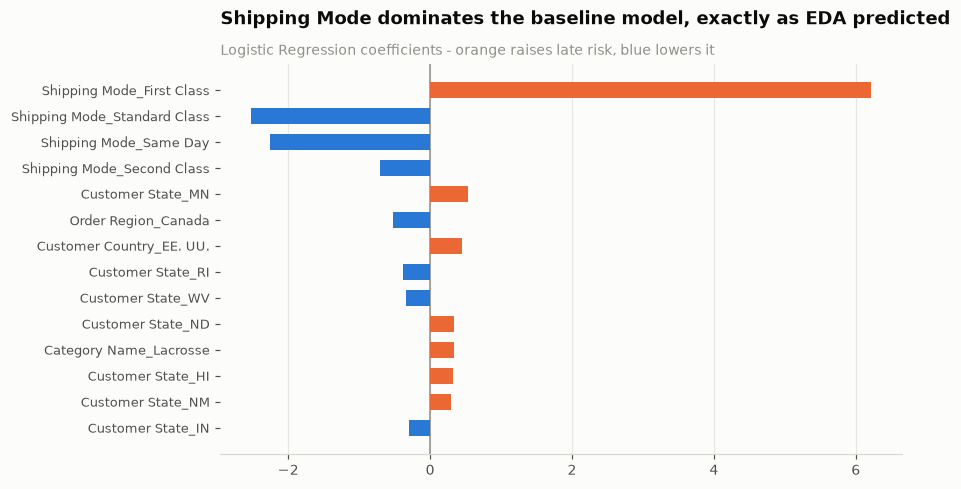

In [49]:
# Which encoded features does the baseline lean on?
# READ: Shipping Mode dominates, exactly as the EDA predicted. EDA and model
# agreeing is the sign the pipeline is behaving.

# Which encoded features does the linear model lean on? (a sanity check, not an interpretation)
coef = pd.Series(logit.coef_[0], index=feature_names)
top  = coef.reindex(coef.abs().sort_values(ascending=False).head(14).index)[::-1]

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(np.arange(len(top)), top.values,
        color=[C_ORANGE if v > 0 else C_BLUE for v in top.values], height=.62, zorder=3)
ax.axvline(0, color=INK_MUTED, linewidth=1)
ax.set_yticks(np.arange(len(top))); ax.set_yticklabels(top.index, fontsize=8.5)
finish(ax, "Shipping Mode dominates the baseline model, exactly as EDA predicted",
       "Logistic Regression coefficients - orange raises late risk, blue lowers it", hgrid=True)
save(fig, "11_smoke_test_coefficients"); plt.show()

---
## 11 · Feature selection

§7 already removed 35 columns for reasons no algorithm could find. These four filters handle the rest.

In [50]:
# FEATURE SELECTION, filters 1 and 2.
# Note there are TWO LEVELS of selection, and this is the second:
#  Level 1 (Section 7) removed 35 columns for reasons NO ALGORITHM could find -
#    leakage, identifiers, PII, constants, exact duplicates. An automatic
#    selector would happily KEEP Delivery Status because it predicts perfectly.
#    That is exactly the trap, which is why level 1 must be manual.
#  Level 2 (here) asks which of the survivors statistically earn their place.
# Filter 1: zero / near-zero variance.  Filter 2: pairwise |r| > 0.95.

from sklearn.feature_selection import VarianceThreshold, SelectFromModel
from sklearn.ensemble import RandomForestClassifier

enc = pd.DataFrame(Xt_train, columns=feature_names)

# --- Filter 1: zero / near-zero variance -----------------------------------
vt = VarianceThreshold(threshold=0.0).fit(Xt_train)
near_zero = [f for f, v in zip(feature_names, enc.var()) if v < 1e-4]
print(f"Filter 1  zero-variance columns      : {(~vt.get_support()).sum()}")
print(f"          near-zero variance (<1e-4) : {len(near_zero)}")

# --- Filter 2: pairwise redundancy among encoded columns -------------------
cm = np.nan_to_num(enc.corr().abs().to_numpy(copy=True))
np.fill_diagonal(cm, 0.0)
redundant = set()
for i in range(len(feature_names)):
    for j in range(i + 1, len(feature_names)):
        if cm[i, j] > 0.95 and feature_names[j] not in redundant:
            redundant.add(feature_names[j])
print(f"Filter 2  |r| > 0.95 redundant pairs : {len(redundant)}  {sorted(redundant)[:6]}")

Filter 1  zero-variance columns      : 0
          near-zero variance (<1e-4) : 0
Filter 2  |r| > 0.95 redundant pairs : 4  ['Customer Country_Puerto Rico', 'Customer State_PR', 'order_quarter', 'order_weekofyear']


In [51]:
# Filters 3 and 4: mutual information, plus embedded importance from TWO
# different model families (L1-penalised linear, and a tree ensemble).
# WHY three criteria rank-averaged: no single method dominates, and it protects
# against the Latitude artefact from Section 9.5 - MI ranks it top, but L1 and
# Random Forest both give it ~zero, so the average demotes it correctly.

# --- Filter 3: mutual information on the ENCODED matrix --------------------
mi_enc = pd.Series(
    mutual_info_classif(Xt_train, y_train, random_state=RANDOM_STATE),
    index=feature_names).sort_values(ascending=False)

# --- Filter 4: embedded importance from two different model families -------
l1 = LogisticRegression(penalty="l1", solver="liblinear", C=0.1,
                        random_state=RANDOM_STATE).fit(Xt_train, y_train)
rf = RandomForestClassifier(n_estimators=120, max_depth=14, min_samples_leaf=20,
                            n_jobs=-1, random_state=RANDOM_STATE).fit(Xt_train, y_train)

rank = pd.DataFrame({
    "mutual_info":  mi_enc,
    "l1_abs_coef":  pd.Series(np.abs(l1.coef_[0]), index=feature_names),
    "rf_importance": pd.Series(rf.feature_importances_, index=feature_names),
}).fillna(0)

# Rank-average the three criteria so no single method dominates.
rank["mean_rank"] = rank.rank(ascending=False).mean(axis=1)
rank = rank.sort_values("mean_rank")

print(f"Filter 3  features with MI > 0            : {(mi_enc > 0).sum()} / {len(feature_names)}")
print(f"Filter 4  features zeroed out by L1       : {(l1.coef_[0] == 0).sum()} / {len(feature_names)}")
print()
rank.head(15).round(5)

Filter 3  features with MI > 0            : 86 / 132
Filter 4  features zeroed out by L1       : 56 / 132



,mutual_info,l1_abs_coef,rf_importance,mean_rank
Shipping Mode_Standard Class,0.11062,0.42145,0.38183,2.00000
Shipping Mode_First Class,0.09889,7.43241,0.25625,2.00000
Shipping Mode_Second Class,0.02822,1.37906,0.11631,3.33333
is_afternoon,0.00657,0.18757,0.03084,7.00000
Latitude,0.11659,0.01946,0.01134,18.66667
order_hour,0.00243,0.03888,0.03655,22.66667
order_quarter,0.00364,0.03796,0.00173,23.00000
Order Region_Western Europe,0.00347,0.07579,0.00066,23.33333
Shipping Mode_Same Day,0.00085,0.15444,0.08270,23.33333
Customer Segment_Consumer,0.00579,0.01248,0.00142,28.00000


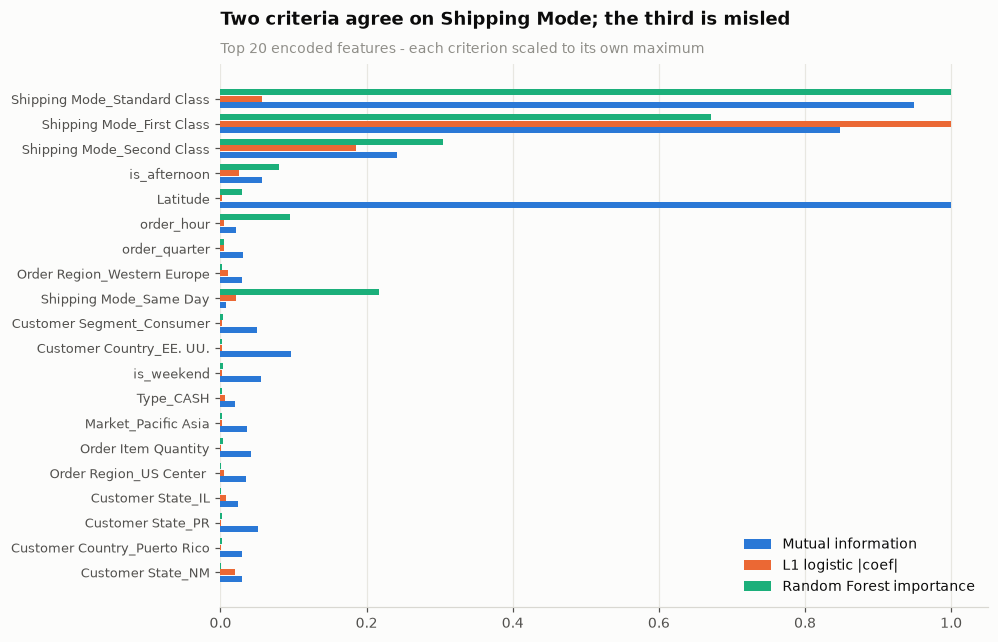

In [52]:
# Plot the three criteria side by side, each scaled to its own maximum.
# READ: L1 and Random Forest agree on Shipping Mode. Mutual information does not
# - and it is the one that is wrong (see Section 9.5).

top_n = 20
top = rank.head(top_n)[::-1]
norm_cols = ["mutual_info", "l1_abs_coef", "rf_importance"]
normed = top[norm_cols] / top[norm_cols].max()

fig, ax = plt.subplots(figsize=(9, 6.4))
y = np.arange(len(top)); h = 0.26
for k, (c, col, lab) in enumerate([(C_BLUE, "mutual_info", "Mutual information"),
                                   (C_ORANGE, "l1_abs_coef", "L1 logistic |coef|"),
                                   (C_AQUA, "rf_importance", "Random Forest importance")]):
    ax.barh(y + (k - 1) * h, normed[col], height=h * 0.92, color=c, label=lab, zorder=3)
ax.set_yticks(y); ax.set_yticklabels(top.index, fontsize=8.5)
ax.legend(loc="lower right")
finish(ax, "Two criteria agree on Shipping Mode; the third is misled",
       f"Top {top_n} encoded features - each criterion scaled to its own maximum", hgrid=True)
save(fig, "12_feature_selection"); plt.show()

L1 and Random Forest agree on `Shipping Mode`; mutual information does not, for the reason given in §9.5. Rank-averaging three criteria avoids relying on any one.

In [53]:
# Does pruning actually HELP? Test it rather than assume it.
# Four candidate feature sets, all derived from TRAIN statistics only, compared
# on the validation set - which is exactly what a validation set is for.
# Set D (Shipping Mode alone, 4 columns) is the key comparison: it quantifies how
# much the other 128 features are really worth.

# Candidate feature sets, all derived from TRAIN statistics only.
sets = {
    "A · all encoded features":        list(feature_names),
    "B · drop redundant (|r|>0.95)":   [f for f in feature_names if f not in redundant],
    "C · top 25 by mean rank":         list(rank.head(25).index),
    "D · Shipping Mode dummies only":  [f for f in feature_names if f.startswith("Shipping Mode")],
}

idx = {f: i for i, f in enumerate(feature_names)}
rows = []
for name, feats in sets.items():
    cols = [idx[f] for f in feats]
    m = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE).fit(Xt_train[:, cols], y_train)
    proba = m.predict_proba(Xt_val[:, cols])[:, 1]
    pred  = m.predict(Xt_val[:, cols])
    rows.append({"feature set": name, "n_features": len(feats),
                 "val_accuracy": accuracy_score(y_val, pred),
                 "val_f1":       f1_score(y_val, pred, zero_division=0),
                 "val_roc_auc":  roc_auc_score(y_val, proba)})

comparison = pd.DataFrame(rows).set_index("feature set")
print(comparison.round(4).to_string())

                                n_features  val_accuracy  val_f1  val_roc_auc
feature set                                                                  
A · all encoded features               132        0.7058  0.6849       0.7471
B · drop redundant (|r|>0.95)          128        0.7045  0.6826       0.7473
C · top 25 by mean rank                 25        0.7058  0.6834       0.7521
D · Shipping Mode dummies only           4        0.6944  0.6664       0.7387


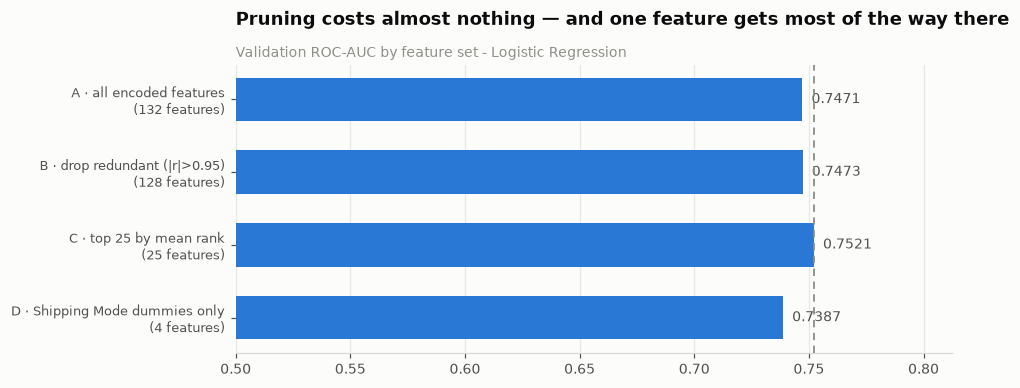

In [54]:
# RESULT: A=0.7471 (132 cols), B=0.7473 (128), C=0.7521 (25), D=0.7387 (4).
# Four one-hot columns get within 0.013 of all 132 - that is the performance
# ceiling, quantified.
# DECISION: keep set A. C is nominally best but +0.0050 is about the standard
# error on 29,842 rows, so we do not claim it wins; and trees perform their own
# implicit selection, so hard-pruning first would throw away that choice.

fig, ax = plt.subplots(figsize=(8.4, 3.4))
y = np.arange(len(comparison))[::-1]
ax.barh(y, comparison["val_roc_auc"], color=C_BLUE, height=.6, zorder=3)
best = comparison["val_roc_auc"].max()
ax.axvline(best, color=INK_MUTED, linestyle=(0, (4, 3)), linewidth=1.2, zorder=4)
ax.set_yticks(y)
ax.set_yticklabels([f"{i}\n({n} features)" for i, n in
                    zip(comparison.index, comparison["n_features"])], fontsize=8.5)
for yi, v in zip(y, comparison["val_roc_auc"]):
    ax.text(v + .004, yi, f"{v:.4f}", va="center", fontsize=9, color=INK_2)
ax.set_xlim(0.5, best * 1.08)
finish(ax, "Pruning costs almost nothing — and one feature gets most of the way there",
       "Validation ROC-AUC by feature set - Logistic Regression", hgrid=True)
save(fig, "13_feature_set_comparison"); plt.show()

| Set | n | Val ROC-AUC |
|---|---|---|
| A · all features | 132 | 0.7471 |
| B · drop redundant | 128 | 0.7473 |
| C · top 25 | 25 | 0.7521 |
| D · `Shipping Mode` only | 4 | 0.7387 |

**Keep A.** C is nominally best but +0.0050 ≈ the standard error, and trees do their own selection.

In [55]:
# Save the selection metadata so the decision is auditable and Notebook 2 can
# reproduce any of the four sets.

selection = {
    "strategy": "domain filter (Section 7) + statistical ranking; full set retained",
    "n_encoded_features": int(len(feature_names)),
    "redundant_r_gt_0.95": sorted(redundant),
    "zero_variance": [f for f, s in zip(feature_names, vt.get_support()) if not s],
    "l1_zeroed": [f for f, c in zip(feature_names, l1.coef_[0]) if c == 0],
    "top25_by_mean_rank": list(rank.head(25).index),
    "validation_comparison": comparison.round(5).reset_index().to_dict("records"),
}
(ART_DIR / "feature_selection.json").write_text(json.dumps(selection, indent=2))
rank.to_csv(ART_DIR / "feature_ranking.csv")
print("Saved artifacts/feature_selection.json and artifacts/feature_ranking.csv")
print(f"\nRetained for modelling: all {len(feature_names)} encoded features "
      f"({len(FEATURES)} raw -> one-hot expansion)")

Saved artifacts/feature_selection.json and artifacts/feature_ranking.csv

Retained for modelling: all 132 encoded features (26 raw -> one-hot expansion)


### 11.4 · Do we need PCA?

Components needed for 90% of variance : 25 / 132
Components needed for 95% of variance : 37 / 132
Variance explained by the first 2      : 22.8%


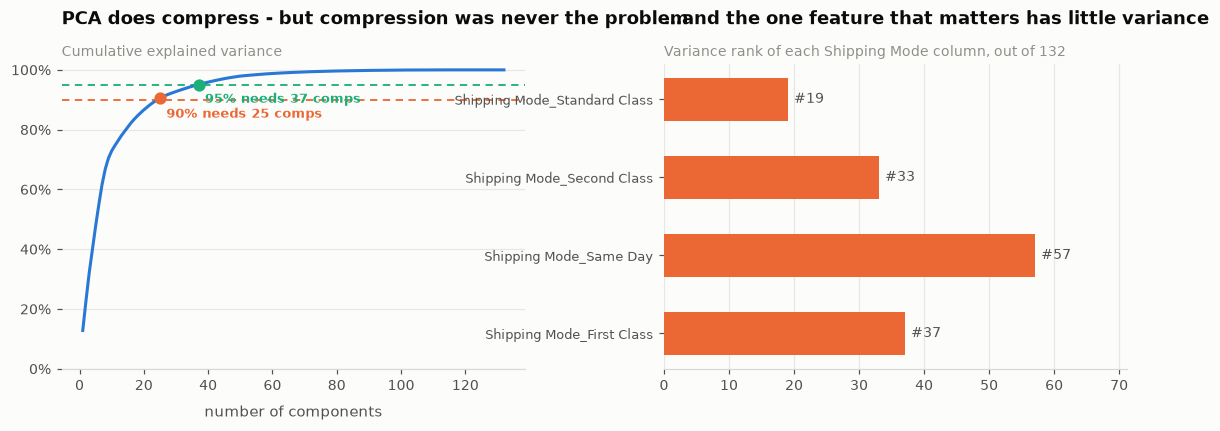

In [56]:
# DO WE NEED PCA? Check the premise before applying the method.
# Left: cumulative explained variance. Right: where the Shipping Mode columns
# rank BY VARIANCE among all 132.
# The right-hand panel is the crux - PCA is UNSUPERVISED, so it selects on
# variance, not on relevance to the target. Same Day is only 5% of rows, so it
# carries very little variance, yet it is one of the few features that matter.
# Nothing stops PCA from discarding it.

from sklearn.decomposition import PCA

pca_full = PCA(random_state=RANDOM_STATE).fit(Xt_train)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n90 = int(np.searchsorted(cum, 0.90) + 1)
n95 = int(np.searchsorted(cum, 0.95) + 1)

print(f"Components needed for 90% of variance : {n90} / {Xt_train.shape[1]}")
print(f"Components needed for 95% of variance : {n95} / {Xt_train.shape[1]}")
print(f"Variance explained by the first 2      : {cum[1]:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6), gridspec_kw={"wspace": 0.3})

ax = axes[0]
ax.plot(range(1, len(cum)+1), cum, color=C_BLUE, linewidth=2, zorder=3)
for frac, c, lab in [(0.90, C_ORANGE, "90%"), (0.95, C_AQUA, "95%")]:
    ax.axhline(frac, color=c, linestyle=(0, (4, 3)), linewidth=1.2, zorder=2)
    k = int(np.searchsorted(cum, frac) + 1)
    ax.plot([k], [cum[k-1]], "o", color=c, markersize=7, zorder=4)
    ax.text(k + 2, frac - .06, f"{lab} needs {k} comps", color=c, fontsize=8.5, fontweight="bold")
ax.set_ylim(0, 1.02)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
finish(ax, "PCA does compress - but compression was never the problem",
       "Cumulative explained variance", xlabel="number of components")

# Where do the Shipping Mode columns rank by their own variance?
var = pd.Series(Xt_train.var(axis=0), index=feature_names).sort_values(ascending=False)
ranks = {f: int(list(var.index).index(f)) + 1 for f in feature_names if f.startswith("Shipping Mode")}
ax = axes[1]
y = np.arange(len(ranks))
ax.barh(y, list(ranks.values()), color=C_ORANGE, height=.55, zorder=3)
ax.set_yticks(y); ax.set_yticklabels(list(ranks.keys()), fontsize=8.5)
for yi, v in zip(y, ranks.values()):
    ax.text(v + 1, yi, f"#{v}", va="center", fontsize=9, color=INK_2)
ax.set_xlim(0, max(ranks.values()) * 1.25)
finish(ax, "…and the one feature that matters has little variance",
       "Variance rank of each Shipping Mode column, out of 132", hgrid=True)
save(fig, "14_pca_variance"); plt.show()

                                   n_inputs  val_roc_auc
representation                                          
SELECTED top 25 features (no PCA)        25       0.7521
PCA -> 50 components                     50       0.7484
No PCA (all 132 features)               132       0.7471
PCA -> 25 components                     25       0.7323
PCA -> 10 components                     10       0.5287
PCA -> 2 components                       2       0.4954


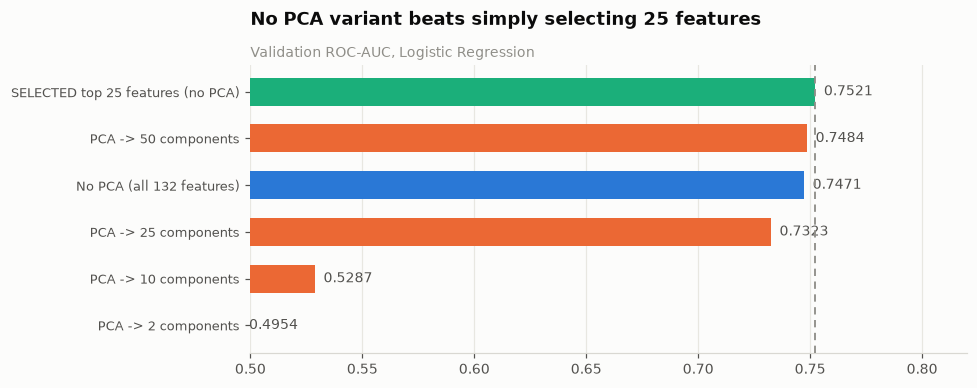

In [57]:
# The decisive PCA test: compare against FEATURE SELECTION at equal dimension.
# RESULT: selected top-25 = 0.7521 vs PCA->25 components = 0.7323. Selection wins
# by 0.020 AND stays interpretable. PCA needs 50 components just to match the
# full model. At 2 components it scores 0.4954 - worse than guessing, because it
# spent its variance budget on the wrong directions.
# VERDICT: PCA rejected. There is also no dimensionality problem to solve
# (132 features vs 109,871 rows) and 115 of 132 columns are one-hot binaries,
# which PCA handles poorly. And it would destroy the deliverable: the report has
# to name WHICH factors drive lateness, not "a mixture of 132 columns".

# The decisive test: does a PCA-compressed model match the plain one?
rows = []
base_m = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE).fit(Xt_train, y_train)
rows.append({"representation": f"No PCA (all {Xt_train.shape[1]} features)", "n_inputs": Xt_train.shape[1],
             "val_roc_auc": roc_auc_score(y_val, base_m.predict_proba(Xt_val)[:, 1])})

for k in sorted({2, 10, 25, 50, n90}):
    pipe = Pipeline([("pca", PCA(n_components=k, random_state=RANDOM_STATE)),
                     ("clf", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])
    pipe.fit(Xt_train, y_train)
    rows.append({"representation": f"PCA -> {k} components", "n_inputs": k,
                 "val_roc_auc": roc_auc_score(y_val, pipe.predict_proba(Xt_val)[:, 1])})

# The honest comparison: 25 SELECTED features vs 25 PCA components.
sel25 = [idx[f] for f in rank.head(25).index]
m25 = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE).fit(Xt_train[:, sel25], y_train)
rows.append({"representation": "SELECTED top 25 features (no PCA)", "n_inputs": 25,
             "val_roc_auc": roc_auc_score(y_val, m25.predict_proba(Xt_val[:, sel25])[:, 1])})

pca_cmp = pd.DataFrame(rows).sort_values("val_roc_auc", ascending=False).set_index("representation")
print(pca_cmp.round(4).to_string())

fig, ax = plt.subplots(figsize=(8.4, 3.4))
y = np.arange(len(pca_cmp))[::-1]
cols = [C_AQUA if "SELECTED" in i else (C_BLUE if "No PCA" in i else C_ORANGE)
        for i in pca_cmp.index]
ax.barh(y, pca_cmp["val_roc_auc"], color=cols, height=.6, zorder=3)
ax.axvline(pca_cmp["val_roc_auc"].iloc[0], color=INK_MUTED,
           linestyle=(0, (4, 3)), linewidth=1.2, zorder=4)
ax.set_yticks(y); ax.set_yticklabels(pca_cmp.index, fontsize=8.5)
for yi, v in zip(y, pca_cmp["val_roc_auc"]):
    ax.text(v + .004, yi, f"{v:.4f}", va="center", fontsize=9, color=INK_2)
ax.set_xlim(0.5, pca_cmp["val_roc_auc"].max() * 1.09)
finish(ax, "No PCA variant beats simply selecting 25 features",
       "Validation ROC-AUC, Logistic Regression", hgrid=True)
save(fig, "15_pca_comparison"); plt.show()

**No.** At 25 inputs, selection scores 0.7521 against PCA's 0.7323 — and stays interpretable.
PCA is unsupervised, so it optimises variance rather than relevance: `Same Day` is 5% of rows and
carries little variance, yet matters. There is also no dimensionality problem to solve
(132 features, 109,871 rows) and 115 of 132 columns are one-hot binaries.

---
## 12 · Save artifacts

Exports are sorted chronologically (the raw CSV is not) and carry `Order Id` + order date so Notebook 2 can do time- or group-aware CV.

In [58]:
# PERSIST the artifacts for Notebook 2.
# Two details that matter:
#  (a) rows are SORTED CHRONOLOGICALLY - the raw CSV is not in date order, and
#      TimeSeriesSplit assumes row order == time order. Without this sort, any
#      time-aware CV in the modelling notebook would be silently WRONG.
#  (b) Order Id and the order date are carried as METADATA (not features) so
#      Notebook 2 can do group-aware or time-aware CV and re-verify the split.
# We save the UNTRANSFORMED splits too, so the pipeline can be refitted inside
# each CV fold - which is the correct way to cross-validate.

import joblib

# 1. Cleaned, split, untransformed frames -- the input to cross-validation.
#
#    Two details that matter for Notebook 2:
#    (a) Rows are SORTED CHRONOLOGICALLY. The raw CSV is not in date order, and
#        TimeSeriesSplit assumes row order == time order. Without this sort, any
#        time-aware CV in the modelling notebook would silently be wrong.
#    (b) We carry 'Order Id' and the order date as METADATA columns (not features)
#        so Notebook 2 can do group-aware or time-aware CV and verify the split.
META = ["Order Id", ORDER_DT]

def export_split(name, Xs, ys, src):
    out = Xs.copy()
    out[TARGET] = ys.to_numpy()
    for m in META:
        out[m] = src[m].to_numpy()
    out = out.sort_values(ORDER_DT).reset_index(drop=True)      # (a)
    assert out[ORDER_DT].is_monotonic_increasing
    try:
        out.to_parquet(ART_DIR / f"{name}.parquet", index=False)
    except Exception as e:      # pyarrow not installed -- CSV is a fine fallback
        print(f"parquet unavailable ({type(e).__name__}); writing CSV instead")
        out.to_csv(ART_DIR / f"{name}.csv", index=False)
    return out

sorted_splits = {
    "train": export_split("train", X_train, y_train, train_df),
    "val":   export_split("val",   X_val,   y_val,   val_df),
    "test":  export_split("test",  X_test,  y_test,  test_df),
}
print("Exported splits are chronologically sorted and carry Order Id + order date as metadata.")

# 2. The fitted preprocessor.
joblib.dump(preprocessor, ART_DIR / "preprocessor.joblib")

# 3. Transformed matrices for fast iteration.
np.savez_compressed(ART_DIR / "transformed.npz",
                    Xt_train=Xt_train, y_train=y_train.to_numpy(),
                    Xt_val=Xt_val,     y_val=y_val.to_numpy(),
                    Xt_test=Xt_test,   y_test=y_test.to_numpy(),
                    feature_names=np.array(feature_names, dtype=object))

# 4. Machine-readable manifest so the modelling notebook is self-documenting.
manifest = {
    "random_state": RANDOM_STATE,
    "source_file": str(RAW_CSV), "source_encoding": "latin-1",
    "rows_raw": int(raw.shape[0]), "rows_after_scope_filter": int(df.shape[0]),
    "excluded_order_statuses": CANCEL_STATUSES,
    "target": TARGET,
    "split_strategy": "chronological (out-of-time) on order date",
    "split_boundaries": {"val_start": str(VAL_START.date()), "test_start": str(TEST_START.date())},
    "split_sizes": {"train": len(X_train), "val": len(X_val), "test": len(X_test)},
    "split_late_rate": {"train": float(y_train.mean()), "val": float(y_val.mean()),
                        "test": float(y_test.mean())},
    "categorical_features": CAT_FEATURES,
    "numeric_features": NUM_FEATURES,
    "engineered_features": ENGINEERED,
    "metadata_columns": META,
    "rows_sorted_chronologically": True,
    "n_features_raw": len(FEATURES), "n_features_encoded": int(Xt_train.shape[1]),
    "dropped_columns": {c: {"reason": r, "justification": j} for c, (r, j) in DROP_REASONS.items()},
    "smoke_test_val_roc_auc": auc,
}
(ART_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2))

print("Written to artifacts/:")
for f in sorted(ART_DIR.iterdir()):
    print(f"  {f.name:<32s} {f.stat().st_size/1024:>9,.0f} KB")
print(f"\nFigures written to figures/: {len(list(FIG_DIR.glob('*.png')))} PNGs")

Exported splits are chronologically sorted and carry Order Id + order date as metadata.
Written to artifacts/:
  column_decision_log.csv                  2 KB
  encoded_dataset.csv                135,332 KB
  encoded_test.csv                    25,708 KB
  encoded_train.csv                   85,497 KB
  encoded_val.csv                     23,210 KB
  feature_ranking.csv                     11 KB
  feature_selection.json                   3 KB
  final_model.joblib                  27,308 KB
  final_test_results.csv                   0 KB
  manifest.json                            6 KB
  model_comparison.csv                     1 KB
  model_summary.json                       1 KB
  preprocessor.joblib                      8 KB
  processed_data_dictionary.csv            2 KB
  processed_dataset.csv               35,278 KB
  test.parquet                           699 KB
  train.parquet                        1,953 KB
  transformed.npz                      9,308 KB
  val.parquet            

In [59]:
# The exact starting code for Notebook 2, including the two valid CV options.
# WHY printed here: it keeps the hand-off in one place and stops the next person
# applying the preprocessor outside the pipeline (which would leak).

# --- How the modelling notebook picks this up -------------------------------
print(r"""
# Notebook 2 (modelling) starts like this:

import joblib, json, pandas as pd
from sklearn.base import clone
from sklearn.pipeline import Pipeline

preprocessor = joblib.load("artifacts/preprocessor.joblib")
manifest     = json.loads(open("artifacts/manifest.json").read())

def load(name):                 # this notebook writes parquet when pyarrow is available, else CSV
    p = Path("artifacts") / f"{name}.parquet"
    return pd.read_parquet(p) if p.exists() else pd.read_csv(f"artifacts/{name}.csv")

train = load("train")
val   = load("val")
test  = load("test")            # DO NOT OPEN UNTIL THE FINAL EVALUATION

TARGET   = manifest["target"]
FEATURES = manifest["categorical_features"] + manifest["numeric_features"]
META     = manifest["metadata_columns"]        # Order Id + order date: NOT features

X_train, y_train = train[FEATURES], train[TARGET]

# Correct cross-validation: the preprocessor goes INSIDE the pipeline, so it is
# re-fitted on each fold rather than once on the whole training set.
model = Pipeline([("prep", clone(preprocessor)), ("clf", SomeClassifier())])

# The exported rows are already sorted by order date, which is what TimeSeriesSplit
# assumes -- so time-aware CV on the training set is valid as-is:
from sklearn.model_selection import TimeSeriesSplit
cv = TimeSeriesSplit(n_splits=5)
scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")

# If you prefer plain K-fold instead, you MUST group by order, or line items of the
# same order land on both sides of a fold and leak the label:
from sklearn.model_selection import StratifiedGroupKFold
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(model, X_train, y_train, cv=cv,
                         groups=train["Order Id"], scoring="roc_auc")
""")


# Notebook 2 (modelling) starts like this:

import joblib, json, pandas as pd
from sklearn.base import clone
from sklearn.pipeline import Pipeline

preprocessor = joblib.load("artifacts/preprocessor.joblib")
manifest     = json.loads(open("artifacts/manifest.json").read())

def load(name):                 # this notebook writes parquet when pyarrow is available, else CSV
    p = Path("artifacts") / f"{name}.parquet"
    return pd.read_parquet(p) if p.exists() else pd.read_csv(f"artifacts/{name}.csv")

train = load("train")
val   = load("val")
test  = load("test")            # DO NOT OPEN UNTIL THE FINAL EVALUATION

TARGET   = manifest["target"]
FEATURES = manifest["categorical_features"] + manifest["numeric_features"]
META     = manifest["metadata_columns"]        # Order Id + order date: NOT features

X_train, y_train = train[FEATURES], train[TARGET]

# Correct cross-validation: the preprocessor goes INSIDE the pipeline, so it is
# re-fitted on each fold rather than once on the whole

### 12.1 · Download-ready exports

`processed_dataset.csv` (human-readable) and `encoded_dataset.csv` (model-ready), plus a zip.

In [60]:
# EXPORT A: the processed dataset in human-readable form - real category names,
# unscaled numbers, with a 'split' column. For Excel, the report appendix and
# sanity checking.

# ---- A. Human-readable processed dataset (one file, with a split label) ----
parts = []
for split_name, frame in sorted_splits.items():
    p = frame.copy()
    p.insert(0, "split", split_name)
    parts.append(p)

processed = pd.concat(parts, ignore_index=True)

# Put the useful columns first so the file reads well when opened.
front = ["split", "Order Id", ORDER_DT, TARGET]
processed = processed[front + [c for c in processed.columns if c not in front]]
processed.to_csv(ART_DIR / "processed_dataset.csv", index=False)

print(f"processed_dataset.csv   {processed.shape[0]:,} rows x {processed.shape[1]} cols")
print(processed["split"].value_counts().reindex(["train", "val", "test"]).to_string())
processed.head(3)

processed_dataset.csv   172,765 rows x 30 cols
split
train    109871
val       29842
test      33052


,split,Order Id,order date (DateOrders),Late_delivery_risk,Type,Shipping Mode,Customer Segment,Customer Country,Customer State,Market,Order Region,Department Name,Category Name,Order Item Quantity,Order Item Discount,Order Item Discount Rate,Product Price,Order Item Total,Latitude,Longitude,order_month,order_day,order_dayofweek,order_hour,order_quarter,order_weekofyear,is_weekend,is_month_end,is_quarter_end,is_afternoon
0,train,1,2015-01-01 00:00:00,0,CASH,Standard Class,Consumer,EE. UU.,NC,LATAM,Central America,Fan Shop,Camping & Hiking,1,60.0,0.20,299.980011,239.979996,35.776661,-81.362625,1,1,3,0,1,1,0,0,0,0
1,train,2,2015-01-01 00:21:00,0,PAYMENT,Standard Class,Consumer,EE. UU.,IL,LATAM,South America,Apparel,Men's Footwear,1,22.1,0.17,129.990005,107.889999,41.832722,-87.980484,1,1,3,0,1,1,0,0,0,0
2,train,2,2015-01-01 00:21:00,0,PAYMENT,Standard Class,Consumer,EE. UU.,IL,LATAM,South America,Golf,Women's Apparel,5,22.5,0.09,50.000000,227.500000,41.832722,-87.980484,1,1,3,0,1,1,0,0,0,0


In [61]:
# EXPORT B: the model-ready matrix - one-hot encoded and standard-scaled.
# NOTE: the val/test rows here are deliberately NOT centred at zero, because the
# scaler was fitted on train only. That is correct. Re-scaling the whole file
# would leak test statistics into training.

# ---- B. Model-ready encoded dataset -----------------------------------------
enc_parts = []
for split_name, Xt, ys in [("train", Xt_train, y_train), ("val", Xt_val, y_val),
                           ("test", Xt_test, y_test)]:
    e = pd.DataFrame(Xt, columns=feature_names)
    e.insert(0, "split", split_name)
    e[TARGET] = ys.to_numpy()
    enc_parts.append(e)

encoded = pd.concat(enc_parts, ignore_index=True)
encoded.to_csv(ART_DIR / "encoded_dataset.csv", index=False)

# Also save each encoded split on its own, for convenience.
for split_name, Xt, ys in [("train", Xt_train, y_train), ("val", Xt_val, y_val),
                           ("test", Xt_test, y_test)]:
    e = pd.DataFrame(Xt, columns=feature_names)
    e[TARGET] = ys.to_numpy()
    e.to_csv(ART_DIR / f"encoded_{split_name}.csv", index=False)

print(f"encoded_dataset.csv     {encoded.shape[0]:,} rows x {encoded.shape[1]} cols")
print(f"  ({len(feature_names)} encoded features + split + {TARGET})")
encoded.iloc[:3, :8]

encoded_dataset.csv     172,765 rows x 134 cols
  (132 encoded features + split + Late_delivery_risk)


,split,Order Item Quantity,Order Item Discount,Order Item Discount Rate,Product Price,Order Item Total,Latitude,Longitude
0,train,-0.13742,-0.774800,-0.874015,-0.609160,-0.609509,-1.162644,0.880290
1,train,-0.13742,-0.979531,-1.299911,-0.780028,-0.965373,-1.177407,0.871515
2,train,-0.13742,-0.815746,-0.874015,-0.694509,-0.799106,-1.198874,0.860168


In [62]:
# A data dictionary for the processed file: what every column means and whether
# it is a feature, the target, or metadata.

# ---- C. A data dictionary for the processed file ----------------------------
processed_dict = []
for c in processed.columns:
    if c == "split":
        role, note = "metadata", "Which split the row belongs to (train / val / test)"
    elif c in META:
        role, note = "metadata", "Identifier / timestamp - NOT a model feature"
    elif c == TARGET:
        role, note = "target", "1 = delivered late, 0 = on time"
    elif c in CAT_FEATURES:
        role, note = "feature (categorical)", f"{processed[c].nunique()} levels"
    elif c in ENGINEERED:
        role, note = "feature (engineered)", "Derived from the order timestamp"
    else:
        role, note = "feature (numeric)", "Original numeric column, retained as-is"
    processed_dict.append({"column": c, "role": role, "dtype": str(processed[c].dtype),
                           "notes": note})

pdict = pd.DataFrame(processed_dict)
pdict.to_csv(ART_DIR / "processed_data_dictionary.csv", index=False)
print(pdict["role"].value_counts().to_string(), "\n")
pdict

role
feature (engineered)     10
feature (categorical)     9
feature (numeric)         7
metadata                  3
target                    1 



,column,role,dtype,notes
0,split,metadata,str,Which split the row belongs to (train / val / ...
1,Order Id,metadata,int64,Identifier / timestamp - NOT a model feature
2,order date (DateOrders),metadata,datetime64[us],Identifier / timestamp - NOT a model feature
3,Late_delivery_risk,target,int64,"1 = delivered late, 0 = on time"
4,Type,feature (categorical),str,4 levels
5,Shipping Mode,feature (categorical),str,4 levels
6,Customer Segment,feature (categorical),str,3 levels
7,Customer Country,feature (categorical),str,2 levels
8,Customer State,feature (categorical),str,46 levels
9,Market,feature (categorical),str,5 levels


In [63]:
# Bundle artifacts + figures into one zip for download and submission.

# ---- D. Bundle everything into one zip for download -------------------------
import zipfile

ZIP_PATH = Path("DataCo_processed_2026-AI-05.zip")
with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED, compresslevel=6) as z:
    for f in sorted(ART_DIR.iterdir()):
        if f.is_file():
            z.write(f, arcname=f"artifacts/{f.name}")
    for f in sorted(FIG_DIR.glob("*.png")):
        z.write(f, arcname=f"figures/{f.name}")

print(f"Created {ZIP_PATH.resolve()}")
print(f"Size: {ZIP_PATH.stat().st_size/1e6:,.1f} MB\n")
with zipfile.ZipFile(ZIP_PATH) as z:
    for i in z.infolist():
        print(f"  {i.filename:<48s} {i.file_size/1024:>9,.0f} KB")

Created D:\ML ASSIGNEMENT\DataCo_processed_2026-AI-05.zip
Size: 48.2 MB

  artifacts/column_decision_log.csv                        2 KB
  artifacts/encoded_dataset.csv                      135,332 KB
  artifacts/encoded_test.csv                          25,708 KB
  artifacts/encoded_train.csv                         85,497 KB
  artifacts/encoded_val.csv                           23,210 KB
  artifacts/feature_ranking.csv                           11 KB
  artifacts/feature_selection.json                         3 KB
  artifacts/final_model.joblib                        27,308 KB
  artifacts/final_test_results.csv                         0 KB
  artifacts/manifest.json                                  6 KB
  artifacts/model_comparison.csv                           1 KB
  artifacts/model_summary.json                             1 KB
  artifacts/preprocessor.joblib                            8 KB
  artifacts/processed_data_dictionary.csv                  2 KB
  artifacts/processed_dataset.c

In `encoded_dataset.csv` the val/test rows are deliberately not centred at zero — the scaler was fitted on train only. Rescaling the whole file would leak.

---
## 13 · Summary

| Step | Result |
|---|---|
| Encoding | OneHot, `min_frequency=20`, unknown-safe |
| Scaling | StandardScaler, 17 numeric |
| Imputation | median / constant |
| Leakage | 4 columns removed, proven |
| Scope | 7,754 cancelled rows removed |
| Split | chronological 64/17/19, order-disjoint |
| Features | 26 raw → 132 encoded |
| Selection | manual + 4 statistical filters |
| PCA | tested, rejected |
| Smoke test | val ROC-AUC ≈ 0.747 |

**Findings for the report**
1. First Class is late 100.0% of the time — always 2 days against a 1-day promise.
2. Second and Standard Class have identical transit times but 80% vs 40% late — only the promise differs.
3. Orders placed after 12:00 are late 6.4 points more often (midday dispatch cut-off).
4. The mode effect is identical in every market and segment → one global SLA fix.
5. Expect ROC-AUC 0.75–0.79; above 0.95 means leakage.

**Limitations**
- No operational covariates (carrier, warehouse, route, weather, capacity) — the ceiling is a property of the data, not the method.
- Target is a derived arithmetic flag, inheriting any error in the recorded shipping dates.
- Store locations are Puerto Rico / USA only.
- Day-of-week volume is uniform, so timestamps may be synthetic.
- Test window has unseen categories and ~40% of earlier volume.

**Hand-off:** `artifacts/` has everything Notebook 2 needs. Test set stays sealed until final evaluation.